# Image–Text Match / Mismatch Detection with Frozen CLIP + Cross-Attention Head

**Goal.** Decide whether an image and a piece of text **match** or **mismatch** in meaning, and return a
calibrated match probability, the CLIP similarity and a 7×7 attention heatmap.

**Out of scope.** Hate, fake-news, misleading, offensive or factual-truth detection. The model measures
*semantic alignment*, not truth.

| Mode | Image | Text | Training data |
|---|---|---|---|
| `A` | plain photo | typed caption | COCO Captions (Karpathy split) |
| `B-cap` | photo with text, **text masked out** | typed caption | TextCaps |
| `B-ocr` | photo with text, **text masked out** | text read from the image (OCR) | TextCaps + TextVQA Rosetta OCR |

Embedded text is inpainted away before CLIP sees the image; otherwise CLIP simply *reads* the words and the
similarity becomes trivially high (typographic shortcut).

**Backbone:** frozen `openai/clip-vit-base-patch32` (never fine-tuned). **Trained part:** a ~2.5 M-parameter
cross-attention head.

**How to run on Kaggle**
1. Settings → Accelerator **GPU (T4 or P100)**, Internet **ON** (phone-verified account).
2. *Save Version → Save & Run All (Commit)*. No cell waits for input. Expected wall time ≈ 2–4 h.
3. When the commit finishes: **Output** tab → download `model_outputs.zip` → unzip into `backend/model_outputs/`.

Every expensive stage writes a `done.json` marker under `CACHE_DIR`, so an interactive re-run skips finished work.

## 1. Environment check, installs, seeds

In [4]:
import os, sys, subprocess, shutil, platform, time, json, gc, random, math, hashlib, zipfile, io, re, importlib, textwrap
import warnings
for _pat in (".*pin_memory.*", ".*quantize_per_tensor.*", ".*IProgress not found.*", ".*non-writable tensors.*"):
    warnings.filterwarnings("ignore", message=_pat)
from pathlib import Path

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print((r.stdout + r.stderr).rstrip())

sh("nvidia-smi || echo 'nvidia-smi not available (no GPU attached?)'")
sh("df -h " + " ".join(p for p in ["/tmp", "/kaggle/working", "/kaggle/temp"] if os.path.exists(p)))

# --- installs (before heavy imports so nothing already-imported gets swapped underneath us) -------------------
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

try:
    import easyocr  # noqa: F401
except ImportError:
    pip_install("easyocr")
for mod, pkg in [("pyarrow", "pyarrow"), ("psutil", "psutil")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        pip_install(pkg)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
import cv2
import PIL
from PIL import Image, ImageOps, ImageDraw
import sklearn
import psutil
import easyocr
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

VERSIONS = {
    "python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
    "easyocr": getattr(easyocr, "__version__", "unknown"), "opencv": cv2.__version__, "numpy": np.__version__,
    "pillow": PIL.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
}
try:
    import tokenizers; VERSIONS["tokenizers"] = tokenizers.__version__
except Exception:
    pass
print(json.dumps(VERSIONS, indent=1))
print("CUDA available:", torch.cuda.is_available(),
      "| GPUs:", torch.cuda.device_count(),
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-")
print("CPUs:", os.cpu_count(), "| RAM total GB:", round(psutil.virtual_memory().total / 1e9, 1))

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

# plotting defaults: thin marks, recessive grid, fixed categorical order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 120, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE), "font.size": 9, "axes.titlesize": 10,
})

Tue Sep 29 10:49:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Configuration — every path and hyperparameter in one place

Any key can be overridden without editing the notebook through the environment variable `MM_CFG`
(a JSON object). This is only a convenience for local testing; a normal Kaggle run uses the defaults below.

In [5]:
CFG = dict(
    SEED=SEED,
    # --- paths -----------------------------------------------------------------------------------------------
    DATA_DIR="/tmp/data", CACHE_DIR="/tmp/cache",
    OUT_DIR="/kaggle/working/model_outputs", ZIP_BASE="/kaggle/working/model_outputs",
    MIN_FREE_GB=45,                       # if /tmp has less, pick the roomiest other scratch disk automatically
    SCRATCH_CANDIDATES=["/tmp", "/kaggle/temp", "/kaggle/tmp", "/root"],
    REQUIRE_GPU=True,                     # fail fast instead of running for 12 h on CPU
    # --- official sources (section 3 of the spec) ------------------------------------------------------------
    URLS={
        "coco_train": "http://images.cocodataset.org/zips/train2014.zip",
        "coco_val": "http://images.cocodataset.org/zips/val2014.zip",
        "karpathy": "https://cs.stanford.edu/people/karpathy/deepimagesent/caption_datasets.zip",
        "textcaps_train": "https://dl.fbaipublicfiles.com/textvqa/data/textcaps/TextCaps_0.1_train.json",
        "textcaps_val": "https://dl.fbaipublicfiles.com/textvqa/data/textcaps/TextCaps_0.1_val.json",
        "textvqa_images": "https://dl.fbaipublicfiles.com/textvqa/images/train_val_images.zip",
        "ocr_train": "https://dl.fbaipublicfiles.com/textvqa/data/TextVQA_Rosetta_OCR_v0.2_train.json",
        "ocr_val": "https://dl.fbaipublicfiles.com/textvqa/data/TextVQA_Rosetta_OCR_v0.2_val.json",
    },
    CLIP_ID="openai/clip-vit-base-patch32",
    # --- preprocessing ----------------------------------------------------------------------------------------
    IMAGE=dict(work_side=336, image_size=224, dilate_px=3, inpaint_radius=3),
    MIN_WORDS=3, MAX_TEXT_TOKENS=77,
    TC_VAL_FRAC=0.10,
    OCR_NOISE_P=0.3, OCR_NOISE_RATE=0.05,
    # --- OCR ---------------------------------------------------------------------------------------------------
    OCR=dict(langs=["en"], min_conf=0.5, min_chars=3, max_side=1024),
    OCR_SOURCE="rosetta",                 # "rosetta" (official) or "easyocr" (fallback)
    AUTO_OCR_FALLBACK=True,               # switch to EasyOCR automatically if Rosetta boxes do not align
    ALIGN_CHECK_N=40, ALIGN_MIN_RATE=0.30,
    # --- extraction / loaders ----------------------------------------------------------------------------------
    EXTRACT_BATCH=256, EXTRACT_CHUNK=2048, NUM_WORKERS=2, TEXT_BATCH=1024, SCORE_BATCH=512,
    # --- pair construction -------------------------------------------------------------------------------------
    HARD_TOPK=20, HARD_POOL=10, FN_TEXT_COS=0.90, MINE_CHUNK=1024, TEXTSWAP_POOL=5, EVAL_POS_PER_IMG=3,
    # --- model ---------------------------------------------------------------------------------------------------
    HEAD=dict(d_model=256, n_layers=2, n_heads=4, d_ffn=1024, dropout=0.1, n_modes=3, itc_dim=128, temp_init=0.07),
    # --- training ------------------------------------------------------------------------------------------------
    BATCH=256, MIX_COCO=2 / 3, LR=2e-4, WEIGHT_DECAY=0.01, WARMUP_STEPS=500, EPOCHS=6, PATIENCE=2,
    ITC_WEIGHT=0.5, POS_WEIGHT=3.0, GRAD_CLIP=1.0, LOG_EVERY=200,
    BASELINE_EPOCHS=2, BASELINE_LR=1e-3,
    # --- evaluation / artifacts ------------------------------------------------------------------------------------
    ECE_BINS=15, N_ERRORS=20, GAP_N=500, LATENCY_RUNS=20,
    DELETE_TRAIN_ZIP_AFTER_CACHE=True,    # COCO train2014.zip is not needed after its cache is verified
    DELETE_ALL_ZIPS_AT_END=True,
    # --- swap vocabulary for "swapped" negatives (saved into config.json) ------------------------------------------
    SWAP_GROUPS={
        "color": ["red", "blue", "green", "yellow", "black", "white", "orange", "pink", "purple", "brown", "gray"],
        "number": ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"],
        "people": ["man", "woman", "boy", "girl", "men", "women"],
        "animal": ["dog", "cat", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "bird"],
        "vehicle": ["car", "bus", "truck", "train", "motorcycle", "bicycle", "airplane", "boat"],
        "food": ["pizza", "sandwich", "cake", "donut", "banana", "apple", "broccoli", "carrot"],
    },
    SWAP_RULES={
        "color_aliases": {"grey": "gray"},
        "people_pairs": {"man": "woman", "woman": "man", "boy": "girl", "girl": "boy", "men": "women", "women": "men"},
        "number_note": "swaps always change the value; 'one' is never a source or target so noun number stays grammatical",
        "plural": "simple plurals kept (dogs->cats, buses, sandwiches); a/an article fixed after a swap",
    },
)
if os.environ.get("MM_CFG"):
    _ov = json.loads(os.environ["MM_CFG"])
    for k, v in _ov.items():
        if isinstance(v, dict) and isinstance(CFG.get(k), dict) and k not in ("URLS",):
            CFG[k] = {**CFG[k], **v}
        else:
            CFG[k] = v
    print("CFG overrides from MM_CFG:", list(_ov))

# --- pick scratch disk -----------------------------------------------------------------------------------------
def free_gb(p):
    try:
        return shutil.disk_usage(p).free / 1e9
    except Exception:
        return -1
_scratch = str(Path(CFG["DATA_DIR"]).parent)
if free_gb(_scratch) < CFG["MIN_FREE_GB"] and "MM_CFG" not in os.environ:
    cands = [(free_gb(p), p) for p in CFG["SCRATCH_CANDIDATES"] if os.path.isdir(p)]
    best = max(cands)
    print(f"WARNING: {_scratch} has only {free_gb(_scratch):.1f} GB free; candidates: {cands}")
    if best[1] != _scratch and best[0] > free_gb(_scratch):
        CFG["DATA_DIR"], CFG["CACHE_DIR"] = f"{best[1]}/data", f"{best[1]}/cache"
        print("-> using", best[1])
DATA, CACHE, OUT = Path(CFG["DATA_DIR"]), Path(CFG["CACHE_DIR"]), Path(CFG["OUT_DIR"])
FIG = OUT / "figures"
for d in (DATA, CACHE, OUT, FIG, OUT / "golden", CACHE / "ckpt"):
    d.mkdir(parents=True, exist_ok=True)
print(f"DATA={DATA} ({free_gb(DATA):.1f} GB free) | CACHE={CACHE} | OUT={OUT}")

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if CFG["REQUIRE_GPU"]:
    assert DEVICE.type == "cuda", "No GPU. Enable Settings -> Accelerator -> GPU (T4/P100) and re-run."
print("device:", DEVICE, "| AMP:", USE_AMP)

def amp():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)

def log_mem(tag=""):
    ram = psutil.Process().memory_info().rss / 1e9
    vm = psutil.virtual_memory()
    g = ""
    if DEVICE.type == "cuda":
        g = f" | GPU alloc {torch.cuda.memory_allocated() / 1e9:.2f} GB, reserved {torch.cuda.memory_reserved() / 1e9:.2f} GB"
    print(f"[mem] {tag} RSS {ram:.2f} GB | system used {vm.used / 1e9:.1f}/{vm.total / 1e9:.1f} GB{g}", flush=True)

def to_py(o):
    """Make numpy / torch values JSON-serialisable."""
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, float):
        return None if not math.isfinite(o) else o
    if isinstance(o, np.ndarray):
        return to_py(o.tolist())
    if isinstance(o, torch.Tensor):
        return to_py(o.detach().cpu().numpy())
    return o

def save_json(obj, path):
    Path(path).write_text(json.dumps(to_py(obj), indent=1))

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()
    plt.close(fig)

log_mem("start")

DATA=/tmp/data (1201.7 GB free) | CACHE=/tmp/cache | OUT=/kaggle/working/model_outputs
device: cuda:0 | AMP: True
[mem] start RSS 0.94 GB | system used 1.5/33.7 GB | GPU alloc 0.00 GB, reserved 0.00 GB


## 3. Shared code → `mismatch_core.py`

The model class, masking, cleaning and the `Predictor` live in one file. The notebook imports it, and the
**same bytes** are copied into `model_outputs/`, so the backend cannot drift from the trained architecture.

In [6]:
%%writefile mismatch_core.py
"""mismatch_core.py -- shared code for the training notebook AND the inference backend.

Contents
  * caption cleaning            (clean_text, keep_caption)
  * image preparation / masking (prepare_image, mask_text_regions, normalize_pixels)
  * frozen-CLIP helpers         (load_clip, clip_image, clip_text)
  * model                       (CrossAttentionHead)
  * calibration                 (apply_calibration)
  * inference                   (Predictor, NoTextInputError)

The notebook writes this file, imports it, and copies it byte-for-byte into model_outputs/,
so training and serving use exactly the same architecture and preprocessing.
Only numpy / torch / transformers / opencv / pillow (+ easyocr at inference) are needed.
"""
from __future__ import annotations

import io
import json
import math
import re
import unicodedata
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps

__version__ = "1.0.0"

MODES = {"A": 0, "B-cap": 1, "B-ocr": 2}
MODE_NAMES = ["A", "B-cap", "B-ocr"]

# CLIPImageProcessor defaults for openai/clip-vit-base-patch32
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)

DEFAULT_IMAGE_CFG = {"work_side": 336, "image_size": 224, "dilate_px": 3, "inpaint_radius": 3}


class NoTextInputError(ValueError):
    """Raised when there is neither a user caption nor text detected in the image."""


# --------------------------------------------------------------------------------------
# Text cleaning
# --------------------------------------------------------------------------------------
_WS = re.compile(r"\s+")


def clean_text(s) -> str:
    """NFKC-normalise, strip, collapse whitespace. (CLIP's tokenizer lower-cases itself.)"""
    if s is None:
        return ""
    s = unicodedata.normalize("NFKC", str(s))
    return _WS.sub(" ", s).strip()


def n_words(s: str) -> int:
    return len(s.split()) if s else 0


def keep_caption(s: str, min_words: int = 3) -> bool:
    return n_words(s) >= min_words


def alnum_len(s: str) -> int:
    return len(re.sub(r"[^0-9A-Za-z]", "", s or ""))


# --------------------------------------------------------------------------------------
# Image preparation and text masking
# --------------------------------------------------------------------------------------
def load_image_bytes(b: bytes) -> Image.Image:
    img = Image.open(io.BytesIO(b))
    img = ImageOps.exif_transpose(img)
    return img.convert("RGB")


def _resize_short(img: Image.Image, side: int) -> Image.Image:
    """Short side -> `side`, long side truncated exactly like transformers' get_resize_output_image_size."""
    w, h = img.size
    if w <= h:
        nw, nh = side, int(side * h / w)
    else:
        nw, nh = int(side * w / h), side
    if (nw, nh) == (w, h):
        return img
    return img.resize((max(1, nw), max(1, nh)), Image.BICUBIC)


def mask_text_regions(arr: np.ndarray, boxes, dilate_px: int = 3, inpaint_radius: int = 3) -> np.ndarray:
    """Inpaint axis-aligned text boxes.

    arr   : HxWx3 uint8 RGB
    boxes : iterable of [x0, y0, x1, y1] in NORMALISED [0,1] image coordinates
    Boxes are converted to pixels, dilated by `dilate_px`, and filled with cv2 TELEA inpainting.
    """
    if boxes is None or len(boxes) == 0:
        return arr
    h, w = arr.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    for b in boxes:
        x0, y0, x1, y1 = [float(v) for v in b[:4]]
        px0 = int(math.floor(min(x0, x1) * w)) - dilate_px
        py0 = int(math.floor(min(y0, y1) * h)) - dilate_px
        px1 = int(math.ceil(max(x0, x1) * w)) + dilate_px
        py1 = int(math.ceil(max(y0, y1) * h)) + dilate_px
        px0, py0 = max(0, px0), max(0, py0)
        px1, py1 = min(w, px1), min(h, py1)
        if px1 > px0 and py1 > py0:
            mask[py0:py1, px0:px1] = 255
    if not mask.any():
        return arr
    return cv2.inpaint(np.ascontiguousarray(arr), mask, inpaint_radius, cv2.INPAINT_TELEA)


def prepare_image(img: Image.Image, boxes=None, image_cfg: dict | None = None) -> np.ndarray:
    """PIL image -> 224x224x3 uint8 (masked if boxes given).

    1. exif_transpose + RGB
    2. down-scale so the short side is at most `work_side` (speeds up inpainting; boxes are normalised)
    3. mask text regions (optional)
    4. CLIPProcessor geometry: resize short side to 224 (bicubic), centre-crop 224
    Normalisation (mean/std) happens on the tensor side in `normalize_pixels`.
    """
    c = dict(DEFAULT_IMAGE_CFG)
    if image_cfg:
        c.update({k: v for k, v in image_cfg.items() if k in c})
    img = ImageOps.exif_transpose(img).convert("RGB")
    if min(img.size) > c["work_side"]:
        img = _resize_short(img, c["work_side"])
    if boxes is not None and len(boxes) > 0:
        img = Image.fromarray(mask_text_regions(np.asarray(img), boxes, c["dilate_px"], c["inpaint_radius"]))
    size = c["image_size"]
    img = _resize_short(img, size)
    w, h = img.size
    left, top = (w - size) // 2, (h - size) // 2             # same integer centre-crop as CLIPProcessor
    img = img.crop((left, top, left + size, top + size))
    return np.array(img, dtype=np.uint8, copy=True)


def normalize_pixels(u8: torch.Tensor) -> torch.Tensor:
    """(N,H,W,3) uint8 -> (N,3,H,W) float32 normalised with CLIP mean/std (on u8's device)."""
    x = u8.permute(0, 3, 1, 2).float().div_(255.0)
    mean = torch.tensor(CLIP_MEAN, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(CLIP_STD, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std


# --------------------------------------------------------------------------------------
# Frozen CLIP helpers (work with transformers 4.x and 5.x)
# --------------------------------------------------------------------------------------
def load_clip(clip_id: str, device="cpu"):
    from transformers import AutoTokenizer, CLIPModel

    model = CLIPModel.from_pretrained(clip_id)
    model.eval().to(device)
    for p in model.parameters():
        p.requires_grad_(False)
    tok = AutoTokenizer.from_pretrained(clip_id)
    return model, tok


def clip_dims(clip) -> dict:
    vc, tc = clip.config.vision_config, clip.config.text_config
    grid = vc.image_size // vc.patch_size
    return {
        "img_dim": vc.hidden_size,
        "txt_dim": tc.hidden_size,
        "proj_dim": clip.config.projection_dim,
        "n_img_tokens": grid * grid + 1,
    }


@torch.no_grad()
def clip_image(clip, pixel_values: torch.Tensor):
    """-> (tokens (N,1+P,Dv) = vision last_hidden_state, pooled (N,proj) L2-normalised)."""
    out = clip.vision_model(pixel_values=pixel_values)
    pooled = clip.visual_projection(out.pooler_output)
    return out.last_hidden_state, F.normalize(pooled.float(), dim=-1)


@torch.no_grad()
def clip_text(clip, tokenizer, texts, device, max_length: int = 77):
    """-> (tokens (N,L,Dt), attention mask (N,L) bool, pooled (N,proj) L2-normalised)."""
    enc = tokenizer(list(texts), padding=True, truncation=True, max_length=max_length, return_tensors="pt")
    ids = enc["input_ids"].to(device)
    am = enc["attention_mask"].to(device)
    out = clip.text_model(input_ids=ids, attention_mask=am)
    pooled = clip.text_projection(out.pooler_output)
    return out.last_hidden_state, am.bool(), F.normalize(pooled.float(), dim=-1)


# --------------------------------------------------------------------------------------
# Cross-attention head
# --------------------------------------------------------------------------------------
class FusionLayer(nn.Module):
    """Pre-LN block: text self-attn -> cross-attn (Q=text, K/V=image) -> FFN, all residual."""

    def __init__(self, d_model=256, n_heads=4, d_ffn=1024, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.self_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.cross_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln3 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ffn), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ffn, d_model), nn.Dropout(dropout)
        )
        self.drop = nn.Dropout(dropout)

    def forward(self, x, img, pad_mask, need_weights=False):
        h = self.ln1(x)
        a, _ = self.self_attn(h, h, h, key_padding_mask=pad_mask, need_weights=False)
        x = x + self.drop(a)
        h = self.ln2(x)
        a, w = self.cross_attn(h, img, img, need_weights=need_weights, average_attn_weights=False)
        x = x + self.drop(a)
        x = x + self.ffn(self.ln3(x))
        return x, w


class CrossAttentionHead(nn.Module):
    """Small trainable head on top of frozen CLIP tokens.

    ITM : text tokens (+mode embedding) attend to image tokens -> masked mean-pool -> [pooled, clip_cos] -> logit
    ITC : mean image token / masked-mean text token -> 128-d, L2-normalised, learnable temperature
    """

    def __init__(self, img_dim=768, txt_dim=512, d_model=256, n_layers=2, n_heads=4, d_ffn=1024,
                 dropout=0.1, n_modes=3, itc_dim=128, temp_init=0.07, n_img_tokens=50, **_ignored):
        super().__init__()
        self.n_img_tokens = n_img_tokens
        self.img_proj = nn.Sequential(nn.Linear(img_dim, d_model), nn.LayerNorm(d_model))
        self.txt_proj = nn.Sequential(nn.Linear(txt_dim, d_model), nn.LayerNorm(d_model))
        self.mode_emb = nn.Embedding(n_modes, d_model)
        nn.init.normal_(self.mode_emb.weight, std=0.02)
        self.layers = nn.ModuleList([FusionLayer(d_model, n_heads, d_ffn, dropout) for _ in range(n_layers)])
        self.ln_out = nn.LayerNorm(d_model)
        self.itm = nn.Linear(d_model + 1, 1)
        self.itc_img = nn.Linear(d_model, itc_dim)
        self.itc_txt = nn.Linear(d_model, itc_dim)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1.0 / temp_init)))

    # --- projections -----------------------------------------------------------------
    def proj_image(self, img_tokens):
        return self.img_proj(img_tokens.to(self.img_proj[0].weight.dtype))

    def proj_text(self, txt_tokens):
        return self.txt_proj(txt_tokens.to(self.txt_proj[0].weight.dtype))

    @staticmethod
    def masked_mean(x, mask):
        m = mask.unsqueeze(-1).to(x.dtype)
        return (x * m).sum(1) / m.sum(1).clamp_min(1.0)

    # --- contrastive branch ------------------------------------------------------------
    def itc_embed(self, img_p=None, txt_p=None, txt_mask=None):
        zi = zt = None
        if img_p is not None:
            zi = F.normalize(self.itc_img(img_p.mean(1)).float(), dim=-1)
        if txt_p is not None:
            zt = F.normalize(self.itc_txt(self.masked_mean(txt_p, txt_mask)).float(), dim=-1)
        return zi, zt

    def scale(self):
        return self.logit_scale.clamp(0, math.log(100.0)).exp()

    # --- matching branch ---------------------------------------------------------------
    def fuse(self, img_p, txt_p, txt_mask, mode_ids, cos, return_attn=False):
        x = txt_p + self.mode_emb(mode_ids).unsqueeze(1).to(txt_p.dtype)
        pad = ~txt_mask
        w = None
        for i, layer in enumerate(self.layers):
            last = i == len(self.layers) - 1
            x, w = layer(x, img_p, pad, need_weights=(return_attn and last))
        pooled = self.masked_mean(self.ln_out(x), txt_mask)
        feat = torch.cat([pooled, cos.to(pooled.dtype).unsqueeze(-1)], dim=-1)
        logit = self.itm(feat).squeeze(-1)
        if not return_attn:
            return logit, None
        return logit, self.heatmap(w, txt_mask)

    def heatmap(self, w, txt_mask):
        """w: (N, heads, L, T_img) last-layer cross-attn -> (N, g, g) over patch tokens, sums to 1."""
        w = w.float().mean(1)                                   # avg heads -> (N, L, T)
        m = txt_mask.float().unsqueeze(-1)
        w = (w * m).sum(1) / m.sum(1).clamp_min(1.0)           # avg valid text tokens -> (N, T)
        w = w[:, 1:]                                            # drop CLS
        w = w / w.sum(-1, keepdim=True).clamp_min(1e-12)
        g = int(round(math.sqrt(w.shape[-1])))
        return w.view(-1, g, g)

    def forward(self, img_tokens, txt_tokens, txt_mask, mode_ids, cos, return_attn=False):
        img_p = self.proj_image(img_tokens)
        txt_p = self.proj_text(txt_tokens)
        return self.fuse(img_p, txt_p, txt_mask, mode_ids, cos, return_attn=return_attn)


def count_parameters(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


# --------------------------------------------------------------------------------------
# Calibration (pure numpy; no pickles)
# --------------------------------------------------------------------------------------
def sigmoid(x):
    x = np.asarray(x, dtype=np.float64)
    return 1.0 / (1.0 + np.exp(-x))


def apply_calibration(score, entry: dict):
    """entry = {"method": "platt", "a":..,"b":..}  or  {"method": "isotonic", "x":[...], "y":[...]}"""
    s = np.asarray(score, dtype=np.float64)
    if entry["method"] == "platt":
        return sigmoid(entry["a"] * s + entry["b"])
    if entry["method"] == "isotonic":
        return np.interp(s, np.asarray(entry["x"], dtype=np.float64), np.asarray(entry["y"], dtype=np.float64))
    if entry["method"] == "sigmoid":
        return sigmoid(s)
    raise ValueError(f"unknown calibration method {entry['method']}")


# --------------------------------------------------------------------------------------
# Predictor (the backend contract)
# --------------------------------------------------------------------------------------
class Predictor:
    """predictor = Predictor(artifacts_dir="model_outputs", device="cpu")
    result = predictor.predict(image: PIL.Image.Image, captions: list[str])
    """

    def __init__(self, artifacts_dir="model_outputs", device="cpu", ocr_reader=None, clip_model=None, tokenizer=None):
        d = Path(artifacts_dir)
        self.dir = d
        self.cfg = json.loads((d / "config.json").read_text())
        self.calibration = json.loads((d / "calibration.json").read_text())
        self.thresholds = json.loads((d / "thresholds.json").read_text())
        self.device = torch.device(device)
        if clip_model is None:
            clip_model, tokenizer = load_clip(self.cfg["clip_id"], self.device)
        self.clip, self.tok = clip_model, tokenizer
        self.head = CrossAttentionHead(**self.cfg["head_kwargs"])
        sd = torch.load(d / "head.pt", map_location="cpu", weights_only=True)
        self.head.load_state_dict(sd)
        self.head.to(self.device).eval()
        self.ocr_cfg = self.cfg["ocr"]
        self.image_cfg = self.cfg["image"]
        self.max_tokens = int(self.cfg.get("max_text_tokens", 77))
        self._reader = ocr_reader

    # --- OCR ---------------------------------------------------------------------------
    @property
    def reader(self):
        if self._reader is None:
            import easyocr

            self._reader = easyocr.Reader(list(self.ocr_cfg.get("langs", ["en"])),
                                          gpu=(self.device.type == "cuda"), verbose=False)
        return self._reader

    def run_ocr(self, image: Image.Image) -> dict:
        img = ImageOps.exif_transpose(image).convert("RGB")
        W, H = img.size
        max_side = int(self.ocr_cfg.get("max_side", 1024))
        if max(W, H) > max_side:
            r = max_side / float(max(W, H))
            img = img.resize((max(1, int(round(W * r))), max(1, int(round(H * r)))), Image.BICUBIC)
        w, h = img.size
        dets = self.reader.readtext(np.asarray(img))
        min_conf = float(self.ocr_cfg.get("min_conf", 0.5))
        boxes, words = [], []
        for pts, txt, conf in dets:
            if float(conf) < min_conf:
                continue
            pts = np.asarray(pts, dtype=np.float64)
            x0, y0 = pts[:, 0].min() / w, pts[:, 1].min() / h
            x1, y1 = pts[:, 0].max() / w, pts[:, 1].max() / h
            boxes.append([float(np.clip(v, 0, 1)) for v in (x0, y0, x1, y1)])
            words.append(str(txt))
        text = clean_text(" ".join(words))
        has_text = alnum_len(text) >= int(self.ocr_cfg.get("min_chars", 3))
        return {"has_text": bool(has_text), "text": text if has_text else "", "boxes": boxes if has_text else []}

    # --- scoring -----------------------------------------------------------------------
    @torch.no_grad()
    def score(self, image: Image.Image, boxes, texts, modes):
        u8 = prepare_image(image, boxes if boxes else None, self.image_cfg)
        pix = normalize_pixels(torch.from_numpy(u8)[None].to(self.device))
        itok, ipool = clip_image(self.clip, pix)
        ttok, tmask, tpool = clip_text(self.clip, self.tok, texts, self.device, self.max_tokens)
        cos = (tpool @ ipool[0]).float()
        n = len(texts)
        mode_ids = torch.tensor([MODES[m] for m in modes], device=self.device)
        logits, heat = self.head(itok.float().expand(n, -1, -1), ttok.float(), tmask, mode_ids, cos, return_attn=True)
        return cos.cpu().numpy(), logits.float().cpu().numpy(), heat.cpu().numpy()

    def predict(self, image: Image.Image, captions=None, ocr_result: dict | None = None) -> dict:
        caps = [clean_text(c) for c in (captions or [])]
        caps = [c for c in caps if c]
        ocr = ocr_result if ocr_result is not None else self.run_ocr(image)
        if not caps and not ocr["has_text"]:
            raise NoTextInputError("No caption was given and no text was detected in the image.")
        texts, modes, sources = [], [], []
        user_mode = "B-cap" if ocr["has_text"] else "A"
        for c in caps:
            texts.append(c); modes.append(user_mode); sources.append("user")
        if ocr["has_text"]:
            texts.append(ocr["text"]); modes.append("B-ocr"); sources.append("ocr")
        cos, logits, heat = self.score(image, ocr["boxes"] if ocr["has_text"] else None, texts, modes)
        results = []
        for i, (t, m, s) in enumerate(zip(texts, modes, sources)):
            p = float(apply_calibration(logits[i], self.calibration[m]))
            thr = float(self.thresholds[m])
            results.append({
                "source": s, "text": t, "mode": m,
                "similarity": round(float(cos[i]), 6),
                "match_probability": round(p, 6),
                "threshold": round(thr, 6),
                "verdict": "MATCH" if p >= thr else "MISMATCH",
                "heatmap": np.round(heat[i], 6).tolist(),
            })
        results.sort(key=lambda r: r["match_probability"], reverse=True)
        return {"text_detected": bool(ocr["has_text"]), "ocr_text": ocr["text"], "results": results}

Overwriting mismatch_core.py


In [7]:
sys.path.insert(0, os.getcwd())
import mismatch_core as mc
importlib.reload(mc)
shutil.copyfile("mismatch_core.py", OUT / "mismatch_core.py")
assert hashlib.sha256(Path("mismatch_core.py").read_bytes()).hexdigest() == \
       hashlib.sha256((OUT / "mismatch_core.py").read_bytes()).hexdigest()
print("mismatch_core", mc.__version__, "imported and copied to", OUT / "mismatch_core.py")

mismatch_core 1.0.0 imported and copied to /kaggle/working/model_outputs/mismatch_core.py


## 4. Download the official files (skipped when already present)

Only the official URLs are used. Downloads resume after an interruption (HTTP `Range`). If a URL has moved,
take the new link from cocodataset.org/#download, textvqa.org/textcaps or textvqa.org/dataset — never a re-upload.

In [8]:
import requests

FILES = {  # key -> local filename
    "coco_train": "train2014.zip", "coco_val": "val2014.zip", "karpathy": "caption_datasets.zip",
    "textcaps_train": "TextCaps_0.1_train.json", "textcaps_val": "TextCaps_0.1_val.json",
    "textvqa_images": "train_val_images.zip",
    "ocr_train": "TextVQA_Rosetta_OCR_v0.2_train.json", "ocr_val": "TextVQA_Rosetta_OCR_v0.2_val.json",
}
PATHS = {k: DATA / v for k, v in FILES.items()}

def download(url, dest: Path, retries=8, chunk=8 << 20):
    if dest.exists() and dest.stat().st_size > 0:
        print(f"  = {dest.name} present ({dest.stat().st_size / 1e9:.2f} GB), skip")
        return
    part = dest.with_name(dest.name + ".part")
    for attempt in range(1, retries + 1):
        have = part.stat().st_size if part.exists() else 0
        headers = {"Range": f"bytes={have}-"} if have else {}
        try:
            with requests.get(url, stream=True, timeout=60, headers=headers, allow_redirects=True) as r:
                if r.status_code == 416:            # already complete
                    break
                r.raise_for_status()
                if have and r.status_code == 200:   # server ignored Range -> restart
                    have = 0
                total = int(r.headers.get("Content-Length", 0)) + have
                mode = "ab" if have else "wb"
                t0, done, next_report = time.time(), have, 0.0
                with open(part, mode) as f:
                    for block in r.iter_content(chunk_size=chunk):
                        f.write(block)
                        done += len(block)
                        if total and done / total >= next_report:
                            sp = (done - have) / max(1e-6, time.time() - t0) / 1e6
                            print(f"    {dest.name}: {done / 1e9:.2f}/{total / 1e9:.2f} GB ({100 * done / total:.0f}%) {sp:.1f} MB/s", flush=True)
                            next_report += 0.2
                if total and part.stat().st_size != total:
                    raise IOError(f"size mismatch {part.stat().st_size} != {total}")
            break
        except Exception as e:
            print(f"  ! attempt {attempt}/{retries} for {dest.name} failed: {e}")
            if attempt == retries:
                raise RuntimeError(f"Could not download {url}. Get the current official link (see markdown above).") from e
            time.sleep(min(60, 5 * attempt))
    part.rename(dest)
    print(f"  + {dest.name} downloaded ({dest.stat().st_size / 1e9:.2f} GB)")

coco_cache_done = (CACHE / "img_coco" / "done.json").exists()
for key, fname in FILES.items():
    if key == "coco_train" and coco_cache_done and not PATHS[key].exists():
        print("  = train2014.zip not needed (COCO cache already complete)")
        continue
    print("->", key)
    download(CFG["URLS"][key], PATHS[key])

# Karpathy split: extract dataset_coco.json from the zip
KARPATHY_JSON = DATA / "dataset_coco.json"
if not KARPATHY_JSON.exists():
    with zipfile.ZipFile(PATHS["karpathy"]) as z:
        member = [n for n in z.namelist() if n.endswith("dataset_coco.json")][0]
        KARPATHY_JSON.write_bytes(z.read(member))
print("Karpathy JSON:", KARPATHY_JSON, f"{KARPATHY_JSON.stat().st_size / 1e6:.1f} MB")

# integrity: every zip must open (central directory readable)
ZIP_KEYS = ["coco_train", "coco_val", "textvqa_images"]
for k in ZIP_KEYS:
    if PATHS[k].exists():
        with zipfile.ZipFile(PATHS[k]) as z:
            print(f"  {k}: {len(z.namelist()):,} members OK")
sh(f"du -sh {DATA}; df -h {DATA}")

-> coco_train
    train2014.zip: 0.01/13.51 GB (0%) 27.5 MB/s
    train2014.zip: 2.71/13.51 GB (20%) 57.8 MB/s
    train2014.zip: 5.41/13.51 GB (40%) 52.6 MB/s
    train2014.zip: 8.11/13.51 GB (60%) 52.9 MB/s
    train2014.zip: 10.81/13.51 GB (80%) 53.4 MB/s
    train2014.zip: 13.51/13.51 GB (100%) 54.2 MB/s
  + train2014.zip downloaded (13.51 GB)
-> coco_val
    val2014.zip: 0.01/6.65 GB (0%) 26.3 MB/s
    val2014.zip: 1.33/6.65 GB (20%) 48.0 MB/s
    val2014.zip: 2.66/6.65 GB (40%) 45.0 MB/s
    val2014.zip: 3.99/6.65 GB (60%) 47.8 MB/s
    val2014.zip: 5.32/6.65 GB (80%) 42.9 MB/s
    val2014.zip: 6.65/6.65 GB (100%) 44.8 MB/s
  + val2014.zip downloaded (6.65 GB)
-> karpathy
    caption_datasets.zip: 0.01/0.04 GB (23%) 11.8 MB/s
    caption_datasets.zip: 0.02/0.04 GB (46%) 16.7 MB/s
    caption_datasets.zip: 0.03/0.04 GB (68%) 19.7 MB/s
    caption_datasets.zip: 0.03/0.04 GB (91%) 21.7 MB/s
    caption_datasets.zip: 0.04/0.04 GB (100%) 22.2 MB/s
  + caption_datasets.zip downloaded (

## 5. Schema checks on every JSON (keys, counts, one sample)

Loaders below are written against the *observed* schema; unexpected layouts fail loudly here instead of
silently producing empty tables later.

In [9]:
def load_json(p):
    with open(p) as f:
        return json.load(f)

def records_of(j):
    """TextVQA/TextCaps files are {'dataset_...': ..., 'data': [...]}; some tools save the bare list."""
    if isinstance(j, dict):
        for k in ("data", "annotations", "images"):
            if isinstance(j.get(k), list):
                return j[k]
        raise KeyError(f"no record list in keys {list(j)[:10]}")
    return j

def short(o, n=400):
    s = json.dumps(o, default=str)
    return s if len(s) <= n else s[:n] + " ..."

def show_schema(name, j):
    recs = records_of(j)
    top = list(j.keys()) if isinstance(j, dict) else "list"
    print(f"--- {name}: top-level={top} | records={len(recs):,}")
    print("    record keys:", sorted(recs[0].keys()))
    print("    sample:", short(recs[0]))
    return recs

kar = load_json(KARPATHY_JSON)
kar_imgs = show_schema("dataset_coco.json", kar)
assert {"filename", "split", "sentences"} <= set(kar_imgs[0]), "unexpected Karpathy schema"
print("    Karpathy split counts:", pd.Series([im["split"] for im in kar_imgs]).value_counts().to_dict())

tc_train_recs = show_schema("TextCaps train", load_json(PATHS["textcaps_train"]))
tc_val_recs = show_schema("TextCaps val", load_json(PATHS["textcaps_val"]))
for recs in (tc_train_recs, tc_val_recs):
    assert "image_id" in recs[0], "TextCaps records need image_id"
    assert ("caption_str" in recs[0]) or ("reference_strs" in recs[0]), "TextCaps records need caption_str or reference_strs"

ocr_recs = {}
for k in ("ocr_train", "ocr_val"):
    recs = show_schema(k, load_json(PATHS[k]))
    recs = [r for r in recs if isinstance(r, dict) and "image_id" in r]   # drop a possible header record
    ocr_recs[k] = recs
    r0 = next((r for r in recs if r.get("ocr_info")), recs[0])
    assert "ocr_tokens" in r0 or "ocr_info" in r0, "OCR records need ocr_tokens / ocr_info"
    if r0.get("ocr_info"):
        print("    ocr_info[0]:", short(r0["ocr_info"][0]))
    n_tok = [len(r.get("ocr_tokens") or []) for r in recs]
    print(f"    images with >=1 OCR token: {np.mean(np.array(n_tok) > 0):.1%} | mean tokens {np.mean(n_tok):.1f}")

ZIP_MEMBERS = {}
for k in ZIP_KEYS:
    if PATHS[k].exists():
        with zipfile.ZipFile(PATHS[k]) as z:
            names = [n for n in z.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png"))]
        ZIP_MEMBERS[k] = {Path(n).name: n for n in names}
        print(f"--- zip {k}: {len(names):,} images, e.g. {names[:2]}")

--- dataset_coco.json: top-level=['images', 'dataset'] | records=123,287
    record keys: ['cocoid', 'filename', 'filepath', 'imgid', 'sentences', 'sentids', 'split']
    sample: {"filepath": "val2014", "sentids": [770337, 771687, 772707, 776154, 781998], "filename": "COCO_val2014_000000391895.jpg", "imgid": 0, "split": "test", "sentences": [{"tokens": ["a", "man", "with", "a", "red", "helmet", "on", "a", "small", "moped", "on", "a", "dirt", "road"], "raw": "A man with a red helmet on a small moped on a dirt road. ", "imgid": 0, "sentid": 770337}, {"tokens": ["man", "ridin ...
    Karpathy split counts: {'train': 82783, 'restval': 30504, 'test': 5000, 'val': 5000}
--- TextCaps train: top-level=['dataset_type', 'dataset_name', 'dataset_version', 'data'] | records=109,765
    record keys: ['caption_id', 'caption_str', 'caption_tokens', 'flickr_300k_url', 'flickr_original_url', 'image_classes', 'image_height', 'image_id', 'image_name', 'image_path', 'image_width', 'reference_strs', 'refer

## 6. Image and caption index tables → `images.parquet`, `captions.parquet`

Splits are **by image**: COCO uses Karpathy (`train`+`restval` / `val` / `test`); TextCaps uses 90 % / 10 % of the
official train (seed 42, grouped by `image_id`) for train / val and the official **val** as our test.

In [10]:
IMAGES_PQ, CAPTIONS_PQ = CACHE / "images.parquet", CACHE / "captions.parquet"

def parse_box(bb, W=None, H=None):
    """Return [x0,y0,x1,y1] normalised to [0,1] from the formats seen in TextVQA-style files."""
    try:
        if isinstance(bb, dict):
            k = {kk.lower(): v for kk, v in bb.items()}
            if "top_left_x" in k:
                x0, y0 = float(k["top_left_x"]), float(k["top_left_y"])
                x1, y1 = x0 + float(k["width"]), y0 + float(k["height"])
            elif {"x", "y", "width", "height"} <= set(k):
                x0, y0 = float(k["x"]), float(k["y"]); x1, y1 = x0 + float(k["width"]), y0 + float(k["height"])
            elif {"x0", "y0", "x1", "y1"} <= set(k):
                x0, y0, x1, y1 = (float(k[c]) for c in ("x0", "y0", "x1", "y1"))
            else:
                return None
        elif isinstance(bb, (list, tuple)) and len(bb) == 4:
            x0, y0, x1, y1 = (float(v) for v in bb)
        elif isinstance(bb, (list, tuple)) and len(bb) == 8:
            xs, ys = bb[0::2], bb[1::2]
            x0, y0, x1, y1 = min(xs), min(ys), max(xs), max(ys)
        else:
            return None
    except (TypeError, ValueError, KeyError):
        return None
    if max(x0, y0, x1, y1) > 1.5:            # pixel coordinates -> normalise
        if not (W and H):
            return None
        x0, x1, y0, y1 = x0 / W, x1 / W, y0 / H, y1 / H
    x0, x1 = sorted((min(max(x0, 0.0), 1.0), min(max(x1, 0.0), 1.0)))
    y0, y1 = sorted((min(max(y0, 0.0), 1.0), min(max(y1, 0.0), 1.0)))
    if x1 - x0 <= 0 or y1 - y0 <= 0:
        return None
    return [round(x0, 5), round(y0, 5), round(x1, 5), round(y1, 5)]

SPLIT_ORDER = {"train": 0, "val": 1, "test": 2}

if IMAGES_PQ.exists() and CAPTIONS_PQ.exists():
    print("index tables exist -> loading")
    images = pd.read_parquet(IMAGES_PQ); captions = pd.read_parquet(CAPTIONS_PQ)
else:
    # ---------------- COCO (Karpathy) ----------------
    kmap = {"train": "train", "restval": "train", "val": "val", "test": "test"}
    rows, caps, missing = [], [], 0
    for im in kar_imgs:
        fn = im["filename"]
        zk = "coco_train" if "train2014" in (im.get("filepath", "") + fn) else "coco_val"
        member = ZIP_MEMBERS.get(zk, {}).get(fn)
        if member is None:
            missing += 1
            continue
        iid = str(im.get("cocoid", Path(fn).stem))
        rows.append(dict(dataset="coco", image_id=iid, split=kmap[im["split"]], zip_key=zk, member=member,
                         has_ocr=False, ocr_str="", n_ocr_tokens=0, boxes_json="[]"))
        for s in im["sentences"]:
            caps.append(dict(dataset="coco", image_id=iid, raw=s.get("raw") or " ".join(s.get("tokens", []))))
    print(f"COCO: {len(rows):,} images, {len(caps):,} captions, {missing} images missing from zips")
    assert missing <= 0.001 * len(kar_imgs), "too many COCO images missing from the zips"

    # ---------------- TextCaps ----------------
    def tc_group(recs):
        out = {}
        for r in recs:
            iid = str(r["image_id"])
            d = out.setdefault(iid, {"caps": [], "W": r.get("image_width"), "H": r.get("image_height"),
                                     "path": r.get("image_path") or r.get("image_name")})
            if r.get("caption_str"):
                d["caps"].append(r["caption_str"])
            for s in r.get("reference_strs") or []:
                d["caps"].append(s)
        for d in out.values():                    # de-duplicate, keep order
            d["caps"] = list(dict.fromkeys(c for c in d["caps"] if c))
        return out
    tc_off_train, tc_off_val = tc_group(tc_train_recs), tc_group(tc_val_recs)
    overlap = set(tc_off_train) & set(tc_off_val)
    if overlap:
        print(f"removing {len(overlap)} official-train images that also appear in official val")
        for i in overlap:
            tc_off_train.pop(i)
    ids = np.array(sorted(tc_off_train))
    perm = np.random.default_rng(SEED).permutation(len(ids))
    n_val = int(round(CFG["TC_VAL_FRAC"] * len(ids)))
    tc_val_ids = set(ids[perm[:n_val]].tolist())

    ocr_map = {}
    for k in ("ocr_train", "ocr_val"):
        for r in ocr_recs[k]:
            ocr_map.setdefault(str(r["image_id"]), r)
    tv = ZIP_MEMBERS.get("textvqa_images", {})
    missing, n_ocr_cov = 0, 0
    for split_src, group in (("train", tc_off_train), ("test", tc_off_val)):
        for iid, d in group.items():
            member = tv.get(f"{iid}.jpg") or (tv.get(Path(d["path"]).name) if d["path"] else None)
            if member is None:
                missing += 1
                continue
            split = ("val" if iid in tc_val_ids else "train") if split_src == "train" else "test"
            o = ocr_map.get(iid)
            tokens, boxes = [], []
            if o is not None:
                n_ocr_cov += 1
                tokens = [str(t) for t in (o.get("ocr_tokens") or [])]
                for info in o.get("ocr_info") or []:
                    b = parse_box(info.get("bounding_box", info.get("bbox")), d["W"], d["H"])
                    if b:
                        boxes.append(b)
                if not tokens and o.get("ocr_info"):
                    tokens = [str(i.get("word", "")) for i in o["ocr_info"] if i.get("word")]
            ocr_str = mc.clean_text(" ".join(tokens))
            has_ocr = mc.alnum_len(ocr_str) >= CFG["OCR"]["min_chars"]
            rows.append(dict(dataset="tc", image_id=iid, split=split, zip_key="textvqa_images", member=member,
                             has_ocr=bool(has_ocr), ocr_str=ocr_str if has_ocr else "", n_ocr_tokens=len(tokens),
                             boxes_json=json.dumps(boxes)))
            for c in d["caps"]:
                caps.append(dict(dataset="tc", image_id=iid, raw=c))
    n_tc = sum(r["dataset"] == "tc" for r in rows)
    print(f"TextCaps: {n_tc:,} images ({missing} missing from zip), OCR records found for {n_ocr_cov:,}")
    assert missing <= 0.01 * (len(tc_off_train) + len(tc_off_val)), "too many TextCaps images missing from the zip"

    images = pd.DataFrame(rows)
    images["_o"] = images.split.map(SPLIT_ORDER)
    images = images.sort_values(["dataset", "_o", "image_id"]).drop(columns="_o").reset_index(drop=True)
    images["img_idx"] = images.groupby("dataset").cumcount().astype(np.int64)
    captions = pd.DataFrame(caps).merge(images[["dataset", "image_id", "img_idx", "split"]], on=["dataset", "image_id"])
    images.to_parquet(IMAGES_PQ, index=False); captions.to_parquet(CAPTIONS_PQ, index=False)

# ---------------- leakage asserts (per dataset, by image id) ----------------
for ds_name, g in images.groupby("dataset"):
    sets = {s: set(g.loc[g.split == s, "image_id"]) for s in ("train", "val", "test")}
    assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"]), \
        f"split leakage in {ds_name}"
    cap_split = captions[captions.dataset == ds_name].groupby("image_id").split.nunique()
    assert (cap_split == 1).all(), f"captions of one image span several splits in {ds_name}"
    print(f"{ds_name}: split image counts {g.split.value_counts().reindex(['train', 'val', 'test']).to_dict()} — disjoint ✓")
del kar, kar_imgs, tc_train_recs, tc_val_recs, ocr_recs; gc.collect()
DS_CODE = {"coco": 0, "tc": 1}
images["ds"] = images.dataset.map(DS_CODE).astype(np.int64)
captions["ds"] = captions.dataset.map(DS_CODE).astype(np.int64)
log_mem("index built")

COCO: 123,287 images, 616,767 captions, 0 images missing from zips
TextCaps: 25,119 images (0 missing from zip), OCR records found for 25,119
coco: split image counts {'train': 113287, 'val': 5000, 'test': 5000} — disjoint ✓
tc: split image counts {'train': 19758, 'val': 2195, 'test': 3166} — disjoint ✓
[mem] index built RSS 3.19 GB | system used 4.0/33.7 GB | GPU alloc 0.00 GB, reserved 0.00 GB


## 7. Dataset exploration

images:
 split     train   val  test
dataset                    
coco     113287  5000  5000
tc        19758  2195  3166 
captions:
 split     train    val   test
dataset                      
coco     566747  25010  25010
tc        98709  10965  15808
TextCaps images with usable OCR: {'test': 0.948, 'train': 0.95, 'val': 0.949}


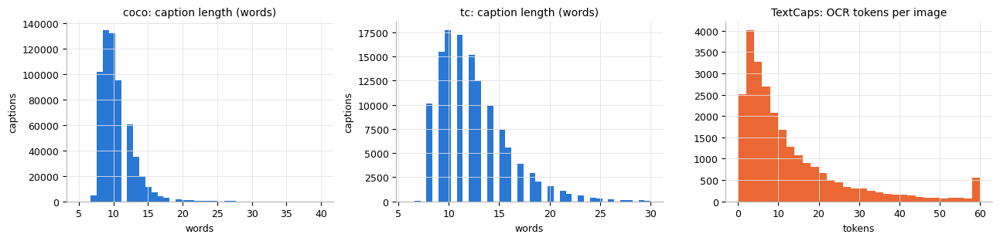

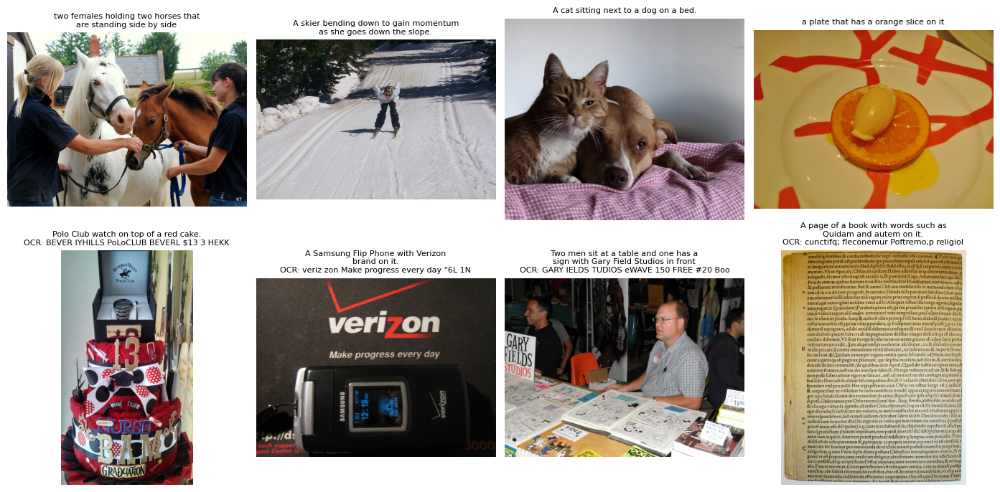

In [11]:
summary = images.groupby(["dataset", "split"]).size().unstack().reindex(columns=["train", "val", "test"])
summary_caps = captions.groupby(["dataset", "split"]).size().unstack().reindex(columns=["train", "val", "test"])
print("images:\n", summary, "\ncaptions:\n", summary_caps)
print("TextCaps images with usable OCR:", images[images.dataset == "tc"].groupby("split").has_ocr.mean().round(3).to_dict())

_zip_handles = {}
def zip_read(zip_key, member):
    if zip_key not in _zip_handles:
        _zip_handles[zip_key] = zipfile.ZipFile(PATHS[zip_key])
    return _zip_handles[zip_key].read(member)

def load_pil(row):
    return mc.load_image_bytes(zip_read(row["zip_key"], row["member"]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (ds_name, g) in zip(axes[:2], captions.groupby("dataset")):
    ax.hist(g.raw.str.split().str.len().clip(upper=40), bins=40, color=PALETTE[0])
    ax.set_title(f"{ds_name}: caption length (words)"); ax.set_xlabel("words"); ax.set_ylabel("captions")
tc_imgs = images[images.dataset == "tc"]
axes[2].hist(tc_imgs.n_ocr_tokens.clip(upper=60), bins=30, color=PALETTE[1])
axes[2].set_title("TextCaps: OCR tokens per image"); axes[2].set_xlabel("tokens")
savefig(fig, "explore_lengths.png")

rng_vis = np.random.default_rng(SEED)
_readable = images.zip_key.map(lambda k: PATHS[k].exists())      # train2014.zip may already be deleted on a resume
sample_rows = pd.concat([images[(images.dataset == "coco") & _readable].sample(4, random_state=SEED),
                         images[(images.dataset == "tc") & images.has_ocr].sample(4, random_state=SEED)])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), sample_rows.iterrows()):
    ax.imshow(load_pil(r)); ax.axis("off")
    cap = captions[(captions.dataset == r.dataset) & (captions.image_id == r.image_id)].raw.iloc[0]
    extra = f"\nOCR: {r.ocr_str[:40]}" if r.has_ocr else ""
    ax.set_title("\n".join(textwrap.wrap(cap, 38)[:2]) + extra, fontsize=8)
savefig(fig, "explore_samples.png")

## 8. Caption cleaning
NFKC → strip → collapse whitespace; drop captions with < 3 words; the tokenizer truncates to 77 tokens.

In [12]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG["CLIP_ID"])

captions["clean"] = captions.raw.map(mc.clean_text)
captions["n_words"] = captions.clean.map(mc.n_words)
captions["keep"] = captions.n_words >= CFG["MIN_WORDS"]
print("dropped (<3 words):", captions.groupby("dataset").keep.apply(lambda s: int((~s).sum())).to_dict())
print("examples dropped:", captions.loc[~captions.keep, "raw"].head(5).tolist())
_samp = captions.clean.sample(min(20000, len(captions)), random_state=SEED).tolist()
_lens = np.array([len(x) for x in tok(_samp, truncation=False)["input_ids"]])
print(f"token length: median {np.median(_lens):.0f}, p99 {np.percentile(_lens, 99):.0f}, "
      f"> {CFG['MAX_TEXT_TOKENS']} tokens (truncated): {np.mean(_lens > CFG['MAX_TEXT_TOKENS']):.2%}")

caps = captions[captions.keep].reset_index(drop=True)
caps["cap_idx"] = np.arange(len(caps), dtype=np.int64)
caps.to_parquet(CACHE / "captions_clean.parquet", index=False)
n_img_nocap = images.merge(caps.groupby(["dataset", "img_idx"]).size().rename("n").reset_index(),
                           on=["dataset", "img_idx"], how="left").n.isna().sum()
print(f"kept captions: {len(caps):,} | images without any kept caption: {n_img_nocap}")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

dropped (<3 words): {'coco': 0, 'tc': 0}
examples dropped: []
token length: median 13, p99 26, > 77 tokens (truncated): 0.00%
kept captions: 742,249 | images without any kept caption: 0


## 9. OCR loading and masking check

Official Rosetta OCR boxes are drawn on five TextCaps images, followed by the masked 224×224 image CLIP will see.
An automatic alignment check compares Rosetta boxes with EasyOCR detections on a few images; if they do not
line up (e.g. a coordinate-convention problem) the notebook falls back to EasyOCR for TextCaps OCR, as the spec
requires — without needing a human to look at the figure during a commit run.

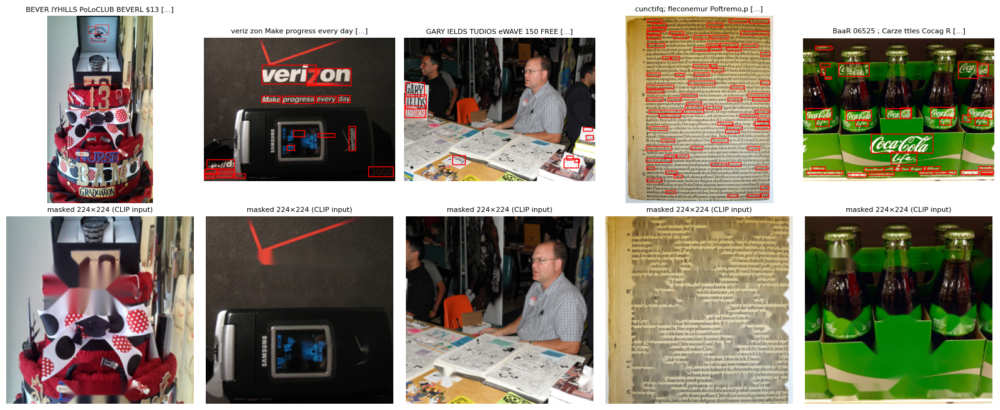

boxes: 313,465 | median area 0.0024 | mean masked fraction per image 0.086
Rosetta/EasyOCR alignment: 165/191 EasyOCR boxes fall inside a Rosetta box (86.4%)
-> keeping official Rosetta OCR
OCR source used for training: rosetta


In [13]:
IMG_CFG = CFG["IMAGE"]
tc_ocr_rows = images[(images.dataset == "tc") & images.has_ocr]
vis = tc_ocr_rows.sample(min(5, len(tc_ocr_rows)), random_state=SEED)
fig, axes = plt.subplots(2, len(vis), figsize=(3.2 * len(vis), 6.6), squeeze=False)
for j, (_, r) in enumerate(vis.iterrows()):
    img = load_pil(r)
    W, H = img.size
    d = ImageDraw.Draw(img)
    for b in json.loads(r.boxes_json):
        d.rectangle([b[0] * W, b[1] * H, b[2] * W, b[3] * H], outline=(255, 0, 0), width=max(2, W // 200))
    axes[0, j].imshow(img); axes[0, j].axis("off"); axes[0, j].set_title(textwrap.shorten(r.ocr_str, 40), fontsize=8)
    axes[1, j].imshow(mc.prepare_image(load_pil(r), json.loads(r.boxes_json), IMG_CFG)); axes[1, j].axis("off")
    axes[1, j].set_title("masked 224×224 (CLIP input)", fontsize=8)
savefig(fig, "ocr_masking_check.png")

all_boxes = [b for s in tc_ocr_rows.boxes_json for b in json.loads(s)]
areas = np.array([(b[2] - b[0]) * (b[3] - b[1]) for b in all_boxes]) if all_boxes else np.zeros(1)
print(f"boxes: {len(all_boxes):,} | median area {np.median(areas):.4f} | mean masked fraction per image "
      f"{np.mean([min(1, sum((b[2] - b[0]) * (b[3] - b[1]) for b in json.loads(s))) for s in tc_ocr_rows.boxes_json]):.3f}")

def box_center_inside(c, boxes, pad=0.02):
    return any(b[0] - pad <= c[0] <= b[2] + pad and b[1] - pad <= c[1] <= b[3] + pad for b in boxes)

_ocr_reader_gpu = None
def get_reader():
    global _ocr_reader_gpu
    if _ocr_reader_gpu is None:
        _ocr_reader_gpu = easyocr.Reader(CFG["OCR"]["langs"], gpu=(DEVICE.type == "cuda"), verbose=False)
    return _ocr_reader_gpu

def easyocr_on_row(r, reader):
    """EasyOCR detections for a table row, in the same normalised format the Predictor uses."""
    p = mc.Predictor.__new__(mc.Predictor)               # reuse Predictor.run_ocr without loading weights
    p.ocr_cfg, p._reader = CFG["OCR"], reader
    return mc.Predictor.run_ocr(p, load_pil(r))

tc_cache_done = (CACHE / "img_tc" / "done.json").exists()
OCR_SOURCE_USED = CFG["OCR_SOURCE"]
if not tc_cache_done:
    reader = get_reader()
    chk = tc_ocr_rows.sample(min(CFG["ALIGN_CHECK_N"], len(tc_ocr_rows)), random_state=SEED + 1)
    hits, total = 0, 0
    for _, r in chk.iterrows():
        e = easyocr_on_row(r, reader)
        rb = json.loads(r.boxes_json)
        for b in e["boxes"]:
            total += 1
            hits += box_center_inside(((b[0] + b[2]) / 2, (b[1] + b[3]) / 2), rb)
    align_rate = hits / max(1, total)
    print(f"Rosetta/EasyOCR alignment: {hits}/{total} EasyOCR boxes fall inside a Rosetta box ({align_rate:.1%})")
    if CFG["OCR_SOURCE"] == "easyocr" or (CFG["AUTO_OCR_FALLBACK"] and total >= 10 and align_rate < CFG["ALIGN_MIN_RATE"]):
        OCR_SOURCE_USED = "easyocr"
        print("-> using EasyOCR for TextCaps OCR strings and masking boxes (this takes a while on ~25k images)")
        eo_path = CACHE / "easyocr_tc.parquet"
        tc_all = images[images.dataset == "tc"]
        done_df = pd.read_parquet(eo_path) if eo_path.exists() else pd.DataFrame(columns=["image_id", "ocr_str", "boxes_json"])
        done_ids, buf, t0 = set(done_df.image_id), [], time.time()
        for i, (_, r) in enumerate(tc_all[~tc_all.image_id.isin(done_ids)].iterrows()):
            e = easyocr_on_row(r, reader)
            buf.append(dict(image_id=r.image_id, ocr_str=e["text"], boxes_json=json.dumps(e["boxes"])))
            if len(buf) >= 1000:
                done_df = pd.concat([done_df, pd.DataFrame(buf)]); done_df.to_parquet(eo_path, index=False); buf = []
                print(f"  EasyOCR {len(done_df):,}/{len(tc_all):,} images, {time.time() - t0:.0f}s", flush=True)
        if buf:
            done_df = pd.concat([done_df, pd.DataFrame(buf)]); done_df.to_parquet(eo_path, index=False)
        m = images.dataset == "tc"
        eo = done_df.set_index("image_id").reindex(images.loc[m, "image_id"])
        images.loc[m, "ocr_str"] = eo.ocr_str.fillna("").values
        images.loc[m, "boxes_json"] = eo.boxes_json.fillna("[]").values
        images.loc[m, "has_ocr"] = [mc.alnum_len(s) >= CFG["OCR"]["min_chars"] for s in images.loc[m, "ocr_str"]]
        images.drop(columns=["ds"]).to_parquet(IMAGES_PQ, index=False)
    else:
        print("-> keeping official Rosetta OCR")
else:
    print("TextCaps cache already built -> alignment check skipped")
(CACHE / "ocr_source.txt").write_text(OCR_SOURCE_USED) if not tc_cache_done else None
OCR_SOURCE_USED = (CACHE / "ocr_source.txt").read_text().strip() if (CACHE / "ocr_source.txt").exists() else OCR_SOURCE_USED
print("OCR source used for training:", OCR_SOURCE_USED)

## 10. Frozen CLIP feature extraction (chunked → disk memmaps)

* Images are decoded **straight from the zips** inside `Dataset.__getitem__`; each DataLoader worker opens its
  own `ZipFile` handle (never shared across processes).
* Tokens (`50×768`, fp16) and pooled embeddings (`512`, L2-normalised) are written into `np.memmap` files in
  chunks of 2,048 images; after each chunk the memmap is flushed, progress is saved (resume support) and memory
  is released. RAM stays flat.
* TextCaps images are masked **before** CLIP sees them.

In [14]:
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPImageProcessor

clip, tok = mc.load_clip(CFG["CLIP_ID"], DEVICE)
DIMS = mc.clip_dims(clip)
T_IMG, D_IMG, D_TXT, P_DIM = DIMS["n_img_tokens"], DIMS["img_dim"], DIMS["txt_dim"], DIMS["proj_dim"]
print("CLIP dims:", DIMS)

# our uint8 pipeline + tensor normalisation must equal CLIPProcessor defaults (no masking, no pre-downscale)
try:
    try:                                  # transformers>=5: PIL reference moved to CLIPImageProcessorPil
        from transformers import CLIPImageProcessorPil as _RefProc
    except ImportError:
        _RefProc = CLIPImageProcessor     # transformers 4.x: PIL-based by default
    proc = _RefProc()                     # library defaults == openai/clip-vit-base-patch32 preprocessor config
    diffs = []
    for _, r in sample_rows.head(3).iterrows():
        a = proc(images=load_pil(r), return_tensors="pt")["pixel_values"].float()
        b = mc.normalize_pixels(torch.from_numpy(mc.prepare_image(load_pil(r), None, {**IMG_CFG, "work_side": 10 ** 6}))[None])
        diffs.append(float((a - b).abs().max()))
    print(f"max |{_RefProc.__name__} - ours| per image:", [round(d, 5) for d in diffs], "(should be ~0)")
except Exception as e:
    print("CLIPProcessor comparison skipped:", e)


class ZipImageDataset(Dataset):
    """Lazy: stores only (zip_key, member, boxes). Decodes + masks + resizes inside __getitem__."""

    def __init__(self, zip_keys, members, boxes, zip_paths, img_cfg):
        self.zip_keys, self.members, self.boxes = list(zip_keys), list(members), list(boxes)
        self.zip_paths = {k: str(v) for k, v in zip_paths.items()}
        self.img_cfg = dict(img_cfg)
        self._z, self._pid = None, None

    def __getstate__(self):
        d = self.__dict__.copy(); d["_z"] = None; d["_pid"] = None
        return d

    def _zip(self, k):
        if self._z is None or self._pid != os.getpid():
            self._z, self._pid = {}, os.getpid()
        if k not in self._z:
            self._z[k] = zipfile.ZipFile(self.zip_paths[k])
        return self._z[k]

    def __len__(self):
        return len(self.members)

    def __getitem__(self, i):
        size = self.img_cfg["image_size"]
        try:
            img = mc.load_image_bytes(self._zip(self.zip_keys[i]).read(self.members[i]))
            arr, ok = mc.prepare_image(img, self.boxes[i], self.img_cfg), 1
        except Exception:
            arr, ok = np.zeros((size, size, 3), np.uint8), 0
        return i, torch.from_numpy(arr), ok


def worker_init_fn(worker_id):
    info = torch.utils.data.get_worker_info()
    if hasattr(info.dataset, "_z"):
        info.dataset._z = None                 # each worker opens its own zip handles
    np.random.seed(SEED + worker_id); random.seed(SEED + worker_id)


def loader_kwargs(persistent):
    nw = CFG["NUM_WORKERS"]
    g = torch.Generator(); g.manual_seed(SEED)
    kw = dict(num_workers=nw, pin_memory=USE_AMP, worker_init_fn=worker_init_fn, generator=g)
    if nw > 0:
        kw.update(persistent_workers=persistent, prefetch_factor=4)
    return kw


def extract_images(name, df, masked):
    d = CACHE / f"img_{name}"; d.mkdir(exist_ok=True)
    if (d / "done.json").exists():
        print(f"[{name}] cache complete -> skip", json.loads((d / "done.json").read_text())["N"], "rows")
        return
    N = len(df)
    save_json(dict(N=N, T=T_IMG, D=D_IMG, P=P_DIM), d / "meta.json")
    tok_p, pool_p, prog_p = d / "tokens.f16", d / "pooled.f16", d / "progress.json"
    start = json.loads(prog_p.read_text())["rows_done"] if prog_p.exists() else 0
    mode = "r+" if (start > 0 and tok_p.exists()) else "w+"
    tokens = np.memmap(tok_p, np.float16, mode, shape=(N, T_IMG, D_IMG))
    pooled = np.memmap(pool_p, np.float16, mode, shape=(N, P_DIM))
    boxes = [json.loads(s) for s in df.boxes_json] if masked else [None] * N
    ds = ZipImageDataset(df.zip_key.values[start:], df.member.values[start:], boxes[start:], PATHS, IMG_CFG)
    loader = DataLoader(ds, batch_size=CFG["EXTRACT_BATCH"], shuffle=False, **loader_kwargs(persistent=True))
    print(f"[{name}] extracting {N - start:,}/{N:,} images (masked={masked}) ...", flush=True)
    written, last_flush, bad, t0 = start, start, [], time.time()
    for step, (idx, u8, ok) in enumerate(loader):
        pix = mc.normalize_pixels(u8.to(DEVICE, non_blocking=True))
        with amp():
            tk, pl = mc.clip_image(clip, pix)
        n = len(idx)
        tokens[written:written + n] = tk.half().cpu().numpy()
        pooled[written:written + n] = pl.half().cpu().numpy()
        bad += (idx[ok == 0] + start).tolist() if (ok == 0).any() else []
        written += n
        if written - last_flush >= CFG["EXTRACT_CHUNK"] or written == N:
            tokens.flush(); pooled.flush()
            save_json({"rows_done": written, "bad": bad}, prog_p)
            last_flush = written
            del tk, pl, pix
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        if step % CFG["LOG_EVERY"] == 0:
            rate = (written - start) / max(1e-6, time.time() - t0)
            print(f"  [{name}] {written:,}/{N:,} ({rate:.0f} img/s)", flush=True)
            log_mem(f"extract {name}")
    del loader, ds; gc.collect()
    if prog_p.exists():
        bad = sorted(set(json.loads(prog_p.read_text()).get("bad", []) + bad))
    # ---- verification: every row written (pooled norm == 1) and no NaN in tokens (chunked -> flat RAM) ----
    tokens = np.memmap(tok_p, np.float16, "r", shape=(N, T_IMG, D_IMG))
    pooled = np.memmap(pool_p, np.float16, "r", shape=(N, P_DIM))
    norms = np.linalg.norm(np.asarray(pooled, dtype=np.float32), axis=1)
    n_unwritten = int((np.abs(norms - 1) > 0.02).sum())
    n_nan = sum(int(np.isnan(tokens[a:a + 4096]).any(axis=(1, 2)).sum()) for a in range(0, N, 4096))
    assert n_unwritten == 0 and n_nan == 0, f"[{name}] verification failed: unwritten={n_unwritten}, nan rows={n_nan}"
    save_json(dict(N=N, T=T_IMG, D=D_IMG, P=P_DIM, bad=bad, masked=masked, seconds=round(time.time() - t0)), d / "done.json")
    print(f"[{name}] done: {N:,} rows verified, {len(bad)} undecodable images, {time.time() - t0:.0f}s")

coco_df = images[images.dataset == "coco"].sort_values("img_idx")
tc_df = images[images.dataset == "tc"].sort_values("img_idx")
extract_images("coco", coco_df, masked=False)
if CFG["DELETE_TRAIN_ZIP_AFTER_CACHE"] and PATHS["coco_train"].exists() and (CACHE / "img_coco" / "done.json").exists():
    PATHS["coco_train"].unlink(); print("deleted train2014.zip (cache verified) to free disk")
extract_images("tc", tc_df, masked=True)
sh(f"du -sh {CACHE}/img_*; df -h {CACHE}")
log_mem("after extraction")

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP dims: {'img_dim': 768, 'txt_dim': 512, 'proj_dim': 512, 'n_img_tokens': 50}
max |CLIPImageProcessor - ours| per image: [0.0, 0.0, 0.0] (should be ~0)
[coco] extracting 123,287/123,287 images (masked=False) ...
  [coco] 256/123,287 (38 img/s)
[mem] extract coco RSS 4.63 GB | system used 6.3/33.7 GB | GPU alloc 0.91 GB, reserved 1.60 GB
  [coco] 51,456/123,287 (140 img/s)
[mem] extract coco RSS 8.71 GB | system used 6.3/33.7 GB | GPU alloc 0.91 GB, reserved 1.48 GB
  [coco] 102,656/123,287 (142 img/s)
[mem] extract coco RSS 8.62 GB | system used 6.3/33.7 GB | GPU alloc 0.91 GB, reserved 1.48 GB
[coco] done: 123,287 rows verified, 0 undecodable images, 901s
deleted train2014.zip (cache verified) to free disk
[tc] extracting 25,119/25,119 images (masked=True) ...
  [tc] 256/25,119 (26 img/s)
[mem] extract tc RSS 4.42 GB | system used 5.3/33.7 GB | GPU alloc 0.91 GB, reserved 1.48 GB
[tc] done: 25,119 rows verified, 0 undecodable images, 491s
9.0G	/tmp/cache/img_coco
1.9G	/tmp/cache/im

## 11. Pooled text embeddings for every caption and OCR string
Text *tokens* are not cached (700k × 77 × 512 would exceed 40 GB); the frozen text encoder runs per batch later.

In [15]:
def encode_texts(name, texts):
    d = CACHE / f"txt_{name}"; d.mkdir(exist_ok=True)
    N = len(texts)
    if (d / "done.json").exists():
        print(f"[txt_{name}] cache complete -> skip"); return
    mm = np.memmap(d / "pooled.f16", np.float16, "w+", shape=(N, P_DIM))
    order = np.argsort([len(t) for t in texts], kind="stable")     # length-sorted batches = less padding
    t0 = time.time()
    for bi, s in enumerate(range(0, N, CFG["TEXT_BATCH"])):
        idx = order[s:s + CFG["TEXT_BATCH"]]
        with amp():
            _, _, pl = mc.clip_text(clip, tok, [texts[i] for i in idx], DEVICE, CFG["MAX_TEXT_TOKENS"])
        mm[idx] = pl.half().cpu().numpy()
        if bi % CFG["LOG_EVERY"] == 0:
            print(f"  [txt_{name}] {min(N, s + len(idx)):,}/{N:,}", flush=True); log_mem("text emb")
    mm.flush()
    norms = np.linalg.norm(np.asarray(mm, dtype=np.float32), axis=1)
    assert np.all(np.abs(norms - 1) < 0.02) and not np.isnan(norms).any()
    save_json(dict(N=N, P=P_DIM, seconds=round(time.time() - t0)), d / "done.json")
    print(f"[txt_{name}] {N:,} embeddings in {time.time() - t0:.0f}s")

encode_texts("cap", caps.clean.tolist())
encode_texts("ocr", tc_df.ocr_str.tolist())
log_mem("after text embeddings")

  [txt_cap] 1,024/742,249
[mem] text emb RSS 4.55 GB | system used 5.6/33.7 GB | GPU alloc 0.72 GB, reserved 1.13 GB
  [txt_cap] 205,824/742,249
[mem] text emb RSS 5.06 GB | system used 5.5/33.7 GB | GPU alloc 0.72 GB, reserved 2.15 GB
  [txt_cap] 410,624/742,249
[mem] text emb RSS 5.25 GB | system used 5.5/33.7 GB | GPU alloc 0.72 GB, reserved 2.39 GB
  [txt_cap] 615,424/742,249
[mem] text emb RSS 5.30 GB | system used 5.6/33.7 GB | GPU alloc 0.72 GB, reserved 2.89 GB
[txt_cap] 742,249 embeddings in 144s
  [txt_ocr] 1,024/25,119
[mem] text emb RSS 4.56 GB | system used 5.6/33.7 GB | GPU alloc 0.72 GB, reserved 5.88 GB
[txt_ocr] 25,119 embeddings in 10s
[mem] after text embeddings RSS 4.55 GB | system used 5.6/33.7 GB | GPU alloc 0.72 GB, reserved 8.67 GB


## 12. Pair construction (easy / hard / swapped / text-swap)

Negatives are always built **inside one split of one dataset**. Hard negatives are mined with pooled CLIP
similarity (top-20 per image, GPU chunks of 1,024) and filtered for false negatives (text–text cosine ≥ 0.90 with
any true caption, or an identical string); one of the top-10 survivors is chosen at random.

In [16]:
DS_NAME = {0: "coco", 1: "tc"}
IMG = {c: images[images.ds == c].sort_values("img_idx").reset_index(drop=True) for c in (0, 1)}
N_IMG = {c: len(IMG[c]) for c in (0, 1)}
BAD = {c: set(json.loads((CACHE / f"img_{DS_NAME[c]}" / "done.json").read_text())["bad"]) for c in (0, 1)}
CAP_TEXT = caps.clean.tolist()
CAP_SID = pd.factorize(caps.clean.str.lower())[0].astype(np.int64)
OCR_TEXT = IMG[1].ocr_str.tolist()
OCR_SID = pd.factorize(IMG[1].ocr_str.str.lower())[0].astype(np.int64)
HAS_OCR = IMG[1].has_ocr.values.astype(bool) & ~np.isin(np.arange(N_IMG[1]), list(BAD[1]))

caps_by_img = {}
for c in (0, 1):
    lst = [np.zeros(0, np.int64)] * N_IMG[c]
    sub = caps[caps.ds == c]
    for img_i, g in sub.groupby("img_idx").cap_idx:
        lst[img_i] = g.values.astype(np.int64)
    caps_by_img[c] = lst
imgs_in = {(c, s): np.array([i for i in np.where(IMG[c].split.values == s)[0]
                             if len(caps_by_img[c][i]) and i not in BAD[c]], dtype=np.int64)
           for c in (0, 1) for s in ("train", "val", "test")}
ocr_imgs_in = {s: np.where((IMG[1].split.values == s) & HAS_OCR)[0].astype(np.int64) for s in ("train", "val", "test")}
print({f"{DS_NAME[c]}/{s}": len(v) for (c, s), v in imgs_in.items()}, "| OCR:", {s: len(v) for s, v in ocr_imgs_in.items()})

# ---- memmap access (opened lazily per process so DataLoader workers get their own handles) ----
_MM = {}
def get_mm(kind, c=None):
    key = (kind, c, os.getpid())
    if key not in _MM:
        if kind in ("tok", "pool"):
            meta = json.loads((CACHE / f"img_{DS_NAME[c]}" / "meta.json").read_text())
            if kind == "tok":
                _MM[key] = np.memmap(CACHE / f"img_{DS_NAME[c]}" / "tokens.f16", np.float16, "r", shape=(meta["N"], meta["T"], meta["D"]))
            else:
                _MM[key] = np.memmap(CACHE / f"img_{DS_NAME[c]}" / "pooled.f16", np.float16, "r", shape=(meta["N"], meta["P"]))
        else:
            n = json.loads((CACHE / f"txt_{kind}" / "done.json").read_text())["N"]
            _MM[key] = np.memmap(CACHE / f"txt_{kind}" / "pooled.f16", np.float16, "r", shape=(n, P_DIM))
    return _MM[key]

def gather(kind, ds_arr, idx_arr):
    """Rows of an image memmap in the given order (sorted unique reads -> only this batch is in RAM)."""
    ds_arr, idx_arr = np.asarray(ds_arr), np.asarray(idx_arr)
    first = get_mm(kind, int(ds_arr[0]))
    out = np.empty((len(idx_arr),) + first.shape[1:], np.float16)
    for c in np.unique(ds_arr):
        m = ds_arr == c
        u, inv = np.unique(idx_arr[m], return_inverse=True)
        out[m] = get_mm(kind, int(c))[u][inv]
    return out

MINE_DT = torch.float16 if DEVICE.type == "cuda" else torch.float32

def mine_hard(c, split):
    """-> {img_idx: array of up to HARD_POOL caption ids} for one dataset split."""
    imgs = imgs_in[(c, split)]
    cap_ids = np.concatenate([caps_by_img[c][i] for i in imgs])
    local = np.full(len(caps), -1, np.int64); local[cap_ids] = np.arange(len(cap_ids))
    maxc = max(len(caps_by_img[c][i]) for i in imgs)
    own = np.full((len(imgs), maxc), -1, np.int64)
    for r_, i in enumerate(imgs):
        cs = caps_by_img[c][i]; own[r_, :len(cs)] = local[cs]
    I = torch.from_numpy(np.asarray(get_mm("pool", c)[imgs], dtype=np.float32)).to(DEVICE, MINE_DT)
    T = torch.from_numpy(np.asarray(get_mm("cap")[cap_ids], dtype=np.float32)).to(DEVICE, MINE_DT)
    sid_t = torch.from_numpy(CAP_SID[cap_ids]).to(DEVICE)
    own_t = torch.from_numpy(own).to(DEVICE)
    k = min(CFG["HARD_TOPK"], len(cap_ids))
    pool = np.full((len(imgs), CFG["HARD_POOL"]), -1, np.int64)
    n_fn = n_cand = 0
    for a in range(0, len(imgs), CFG["MINE_CHUNK"]):
        b = min(len(imgs), a + CFG["MINE_CHUNK"])
        S = I[a:b] @ T.T                                                 # fp16 on GPU: 1024 x 566k = 1.2 GB
        o = own_t[a:b]; valid = o >= 0
        rows = torch.arange(b - a, device=DEVICE)[:, None].expand_as(o)
        S[rows[valid], o[valid]] = -float("inf")                       # own captions are positives
        topv, topi = S.topk(k, dim=1)
        cand = T[topi].float()                                          # (n,k,P)
        ownE = T[o.clamp_min(0)].float()                                # (n,maxc,P)
        tt = torch.einsum("nkp,nmp->nkm", cand, ownE).masked_fill(~valid[:, None, :], -2).amax(-1)
        same_str = ((sid_t[topi][:, :, None] == sid_t[o.clamp_min(0)][:, None, :]) & valid[:, None, :]).any(-1)
        reject = (tt >= CFG["FN_TEXT_COS"]) | same_str | torch.isinf(topv)
        n_fn += int(((tt >= CFG["FN_TEXT_COS"]) | same_str).sum()); n_cand += reject.numel()
        ok = (~reject).cpu().numpy(); ids = cap_ids[topi.cpu().numpy()]
        rank = np.cumsum(ok, axis=1) - 1
        rr, cc = np.nonzero(ok & (rank < CFG["HARD_POOL"]))
        pool[a + rr, rank[rr, cc]] = ids[rr, cc]
    del I, T, S
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    nsurv = (pool >= 0).sum(1)
    print(f"  hard[{DS_NAME[c]}/{split}]: {len(imgs):,} imgs, false-negative filter rejected {n_fn / max(1, n_cand):.1%} "
          f"of top-{k}, survivors/img mean {nsurv.mean():.1f}, imgs with none {(nsurv == 0).sum()}")
    return imgs, pool

def mine_textswap(split):
    imgs = ocr_imgs_in[split]
    if len(imgs) < 2:
        return imgs, np.full((len(imgs), CFG["TEXTSWAP_POOL"]), -1, np.int64)
    E = torch.from_numpy(np.asarray(get_mm("ocr")[imgs], dtype=np.float32)).to(DEVICE, MINE_DT)
    sid = torch.from_numpy(OCR_SID[imgs]).to(DEVICE)
    k = min(CFG["HARD_TOPK"], len(imgs) - 1)
    pool = np.full((len(imgs), CFG["TEXTSWAP_POOL"]), -1, np.int64)
    for a in range(0, len(imgs), CFG["MINE_CHUNK"]):
        b = min(len(imgs), a + CFG["MINE_CHUNK"])
        S = (E[a:b] @ E.T).float()
        S[torch.arange(b - a, device=DEVICE), torch.arange(a, b, device=DEVICE)] = -float("inf")
        topv, topi = S.topk(k, dim=1)
        reject = (topv >= CFG["FN_TEXT_COS"]) | (sid[topi] == sid[a:b, None]) | torch.isinf(topv)
        ok = (~reject).cpu().numpy(); ids = imgs[topi.cpu().numpy()]
        rank = np.cumsum(ok, axis=1) - 1
        rr, cc = np.nonzero(ok & (rank < CFG["TEXTSWAP_POOL"]))
        pool[a + rr, rank[rr, cc]] = ids[rr, cc]
    print(f"  text_swap[{split}]: {len(imgs):,} OCR images, survivors/img mean {(pool >= 0).sum(1).mean():.1f}")
    return imgs, pool

PAIR_DIR = CACHE / "pairs"; PAIR_DIR.mkdir(exist_ok=True)
if (PAIR_DIR / "pools_done.json").exists():
    z = np.load(PAIR_DIR / "pools.npz"); HARD = {0: z["hard0"], 1: z["hard1"]}; TSWAP = z["tswap"]
    print("negative pools loaded from cache")
else:
    HARD = {c: np.full((N_IMG[c], CFG["HARD_POOL"]), -1, np.int64) for c in (0, 1)}
    TSWAP = np.full((N_IMG[1], CFG["TEXTSWAP_POOL"]), -1, np.int64)
    for c in (0, 1):
        for s in ("train", "val", "test"):
            ii, pl = mine_hard(c, s); HARD[c][ii] = pl
    for s in ("train", "val", "test"):
        ii, pl = mine_textswap(s); TSWAP[ii] = pl
    np.savez(PAIR_DIR / "pools.npz", hard0=HARD[0], hard1=HARD[1], tswap=TSWAP)
    save_json({"ok": True}, PAIR_DIR / "pools_done.json")

# ---------------- swapped negatives (rule based, deterministic given the RNG) ----------------
SW = CFG["SWAP_GROUPS"]; SW_RULES = CFG["SWAP_RULES"]
NO_PLURAL = {"sheep", "broccoli"}
NUM_EXCLUDE = {"one"}
def plural(w):
    if w in NO_PLURAL:
        return w
    return w + "es" if w.endswith(("s", "sh", "ch", "x")) else w + "s"
LEX = {}
for g, words in SW.items():
    for w in words:
        if g in ("animal", "vehicle", "food"):
            LEX.setdefault(plural(w), (g, w, True))
        LEX[w] = (g, w, False)
for alias, canon in SW_RULES["color_aliases"].items():
    LEX[alias] = ("color", canon, False)
WORD_RE = re.compile(r"[A-Za-z]+")

def match_case(src, new):
    if len(src) > 1 and src.isupper():
        return new.upper()
    return new[0].upper() + new[1:] if src[0].isupper() else new

def swap_caption(text, r):
    toks = list(WORD_RE.finditer(text))
    cands = [i for i, m in enumerate(toks) if m.group(0).lower() in LEX and m.group(0).lower() not in NUM_EXCLUDE]
    if not cands:
        return None
    i = cands[r.randrange(len(cands))]
    m = toks[i]; word = m.group(0)
    g, canon, is_pl = LEX[word.lower()]
    if g == "people":
        new = SW_RULES["people_pairs"][word.lower()]
    else:
        opts = [w for w in SW[g] if w != canon and w not in NUM_EXCLUDE]
        new = opts[r.randrange(len(opts))]
        if is_pl:
            new = plural(new)
    new = match_case(word, new)
    s = text[:m.start()] + new + text[m.end():]
    if i > 0 and toks[i - 1].group(0).lower() in ("a", "an") and toks[i - 1].end() + 1 == m.start():
        art = toks[i - 1]
        want = match_case(art.group(0), "an" if new[0].lower() in "aeiou" else "a")
        s = s[:art.start()] + want + s[art.end():]
    return s, g, word.lower(), new.lower()

# ---------------- negative samplers ----------------
def own_sids(c, img):
    return {int(CAP_SID[x]) for x in caps_by_img[c][img]}

def neg_easy(c, split, img, r):
    pool = imgs_in[(c, split)]; own = own_sids(c, img); cap = None
    for _ in range(20):
        j = int(pool[r.randrange(len(pool))])
        if j == img:
            continue
        cs = caps_by_img[c][j]; cap = int(cs[r.randrange(len(cs))])
        if CAP_SID[cap] not in own:
            return cap
    return cap

def neg_hard(c, img, r, exclude=None):
    pool = [int(x) for x in HARD[c][img] if x >= 0 and x != exclude]
    return pool[r.randrange(len(pool))] if pool else None

def neg_swapped(c, img, r):
    cs = list(caps_by_img[c][img]); r.shuffle(cs)
    for cap in cs:
        res = swap_caption(CAP_TEXT[cap], r)
        if res:
            return res + (int(cap),)
    return None

def neg_textswap(split, img, r):
    pool = [int(x) for x in TSWAP[img] if x >= 0]
    if pool and r.random() < 0.5:
        return pool[r.randrange(len(pool))], "nearest"
    cand = ocr_imgs_in[split]; e = np.asarray(get_mm("ocr")[img], dtype=np.float32); j = None
    for _ in range(20):
        j = int(cand[r.randrange(len(cand))])
        if j != img and OCR_SID[j] != OCR_SID[img] and float(np.asarray(get_mm("ocr")[j], np.float32) @ e) < CFG["FN_TEXT_COS"]:
            break
    return j, "random"

def noisy_ocr(s, r, rate=CFG["OCR_NOISE_RATE"]):
    out = []
    for ch in s:
        if r.random() < rate:
            op = r.randrange(3)
            if op == 0:
                continue                                     # drop
            if op == 1 or not ch.isalpha():
                out.append(r.choice("abcdefghijklmnopqrstuvwxyz0123456789"))   # substitute
            else:
                out.append(ch.swapcase())                    # change case
        else:
            out.append(ch)
    return "".join(out) or s

# ---------------- evaluation tables (built once, saved) ----------------
def build_eval_table(split, seed):
    r = random.Random(seed); rows = []
    def add(c, img, mode, text, label, ntype, group="", src=-1):
        rows.append(dict(ds=c, img_idx=int(img), mode=mode, text=text, label=int(label), neg_type=ntype,
                         swap_group=group, src=int(src)))
    for c in (0, 1):
        mode = "A" if c == 0 else "B-cap"
        for img in imgs_in[(c, split)]:
            img = int(img)
            cs = list(caps_by_img[c][img]); r.shuffle(cs)
            for cap in cs[:CFG["EVAL_POS_PER_IMG"]]:
                add(c, img, mode, CAP_TEXT[cap], 1, "pos", src=cap)
            ce = neg_easy(c, split, img, r); add(c, img, mode, CAP_TEXT[ce], 0, "easy", src=ce)
            h = neg_hard(c, img, r)
            if h is None:
                h = neg_easy(c, split, img, r); add(c, img, mode, CAP_TEXT[h], 0, "easy", src=h)
            else:
                add(c, img, mode, CAP_TEXT[h], 0, "hard", src=h)
            sw = neg_swapped(c, img, r)
            if sw:
                add(c, img, mode, sw[0], 0, "swapped", group=sw[1], src=sw[4])
            else:
                h2 = neg_hard(c, img, r, exclude=h)
                if h2 is None:
                    h2 = neg_easy(c, split, img, r); add(c, img, mode, CAP_TEXT[h2], 0, "easy", src=h2)
                else:
                    add(c, img, mode, CAP_TEXT[h2], 0, "hard", src=h2)
    for img in ocr_imgs_in[split]:
        img = int(img)
        add(1, img, "B-ocr", OCR_TEXT[img], 1, "pos", src=img)
        j, sub = neg_textswap(split, img, r)
        add(1, img, "B-ocr", OCR_TEXT[j], 0, "text_swap", group=sub, src=j)
    df = pd.DataFrame(rows)
    df["dataset"] = df.ds.map(DS_NAME)
    df["image_id"] = [IMG[c].image_id.values[i] for c, i in zip(df.ds, df.img_idx)]
    df["split"] = split
    df["key"] = df.ds.astype(np.int64) * 10_000_000 + df.img_idx
    df.insert(0, "pair_id", [f"{split}-{i:07d}" for i in range(len(df))])
    return df

if (PAIR_DIR / "val.parquet").exists() and (PAIR_DIR / "test.parquet").exists():
    val_df, test_df = pd.read_parquet(PAIR_DIR / "val.parquet"), pd.read_parquet(PAIR_DIR / "test.parquet")
else:
    val_df, test_df = build_eval_table("val", SEED + 1000), build_eval_table("test", SEED + 2000)
    val_df.to_parquet(PAIR_DIR / "val.parquet", index=False); test_df.to_parquet(PAIR_DIR / "test.parquet", index=False)
test_df.to_csv(OUT / "test_pairs.csv", index=False)
for name, df in (("val", val_df), ("test", test_df)):
    print(f"--- {name}: {len(df):,} pairs, positive rate {df.label.mean():.3f}")
    print(df.groupby(["mode", "neg_type"]).size().unstack(fill_value=0))
for t in ("easy", "hard", "swapped", "text_swap"):
    ex = test_df[test_df.neg_type == t].head(2)
    for _, rr in ex.iterrows():
        truth = test_df[(test_df.key == rr.key) & (test_df.label == 1) & (test_df["mode"] == rr["mode"])].text.iloc[0]
        print(f"[{t}] true: {truth[:70]!r}\n        neg:  {rr.text[:70]!r}")
print("swap groups in test:", test_df[test_df.neg_type == "swapped"].swap_group.value_counts().to_dict())

# ---------------- training plan: offline negatives resampled every epoch with seed SEED + epoch ----------------
B = CFG["BATCH"]
N_COCO_B = int(round(B * CFG["MIX_COCO"]))
N_BCAP_B = (B - N_COCO_B) // 2
N_BOCR_B = B - N_COCO_B - N_BCAP_B
if len(ocr_imgs_in["train"]) == 0:
    N_BCAP_B, N_BOCR_B = N_BCAP_B + N_BOCR_B, 0
STEPS_PER_EPOCH = math.ceil(len(imgs_in[(0, "train")]) / N_COCO_B)
print(f"batch mix: COCO {N_COCO_B} | B-cap {N_BCAP_B} | B-ocr {N_BOCR_B}; steps/epoch {STEPS_PER_EPOCH}")

def build_train_plan(epoch):
    r = random.Random(SEED + epoch); nrng = np.random.default_rng(SEED + epoch)
    coco = nrng.permutation(imgs_in[(0, "train")]); tcc = nrng.permutation(imgs_in[(1, "train")])
    tco = nrng.permutation(ocr_imgs_in["train"])
    P = {k: [] for k in ("ds", "img", "kind", "pos", "neg", "ntype")}
    def cap_item(c, img):
        cs = caps_by_img[c][img]
        P["ds"].append(c); P["img"].append(img); P["kind"].append(0)
        P["pos"].append(CAP_TEXT[cs[r.randrange(len(cs))]])
        t = r.randrange(3); neg = typ = None
        if t == 2:
            sw = neg_swapped(c, img, r)
            if sw:
                neg, typ = sw[0], "swapped"
            else:
                t = 1
        if t == 1:
            h = neg_hard(c, img, r)
            if h is not None:
                neg, typ = CAP_TEXT[h], "hard"
            else:
                t = 0
        if t == 0:
            neg, typ = CAP_TEXT[neg_easy(c, "train", img, r)], "easy"
        P["neg"].append(neg); P["ntype"].append(typ)
    def ocr_item(img):
        j, _ = neg_textswap("train", img, r)
        pos, neg = OCR_TEXT[img], OCR_TEXT[j]
        if r.random() < CFG["OCR_NOISE_P"]:
            pos = noisy_ocr(pos, r)
        if r.random() < CFG["OCR_NOISE_P"]:
            neg = noisy_ocr(neg, r)
        P["ds"].append(1); P["img"].append(img); P["kind"].append(1); P["pos"].append(pos); P["neg"].append(neg)
        P["ntype"].append("text_swap")
    ic = ib = io_ = 0
    for _ in range(STEPS_PER_EPOCH):
        for _ in range(N_COCO_B):
            cap_item(0, int(coco[ic % len(coco)])); ic += 1
        for _ in range(N_BCAP_B):
            cap_item(1, int(tcc[ib % len(tcc)])); ib += 1
        for _ in range(N_BOCR_B):
            ocr_item(int(tco[io_ % len(tco)])); io_ += 1
    for k in ("ds", "img", "kind"):
        P[k] = np.asarray(P[k], dtype=np.int64)
    P["key"] = P["ds"] * 10_000_000 + P["img"]
    return P

_t0 = time.time(); _p0 = build_train_plan(0)
print(f"epoch-0 plan: {len(_p0['pos']):,} items in {time.time() - _t0:.1f}s; offline negative types:",
      pd.Series(_p0["ntype"]).value_counts().to_dict())
print("noisy OCR example:", [(a, b) for a, b in zip(_p0["pos"], _p0["kind"]) if b == 1][:2])
del _p0
log_mem("pairs built")

{'coco/train': 113287, 'coco/val': 5000, 'coco/test': 5000, 'tc/train': 19758, 'tc/val': 2195, 'tc/test': 3166} | OCR: {'train': 18774, 'val': 2083, 'test': 3002}
  hard[coco/train]: 113,287 imgs, false-negative filter rejected 12.4% of top-20, survivors/img mean 9.9, imgs with none 34
  hard[coco/val]: 5,000 imgs, false-negative filter rejected 11.1% of top-20, survivors/img mean 9.9, imgs with none 0
  hard[coco/test]: 5,000 imgs, false-negative filter rejected 11.5% of top-20, survivors/img mean 9.9, imgs with none 0
  hard[tc/train]: 19,758 imgs, false-negative filter rejected 1.1% of top-20, survivors/img mean 10.0, imgs with none 0
  hard[tc/val]: 2,195 imgs, false-negative filter rejected 0.8% of top-20, survivors/img mean 10.0, imgs with none 0
  hard[tc/test]: 3,166 imgs, false-negative filter rejected 1.2% of top-20, survivors/img mean 10.0, imgs with none 0
  text_swap[train]: 18,774 OCR images, survivors/img mean 4.1
  text_swap[val]: 2,083 OCR images, survivors/img mean 4.

## 13. Baseline 1 — CLIP cosine threshold

Shared utilities first: metrics, calibration, and `score_table`, which scores any pair table with any subset of
models in **one** pass of the text encoder. Sections 13–16 only touch **val**; test is scored exactly once in §17.

In [17]:
MODE_NAMES = mc.MODE_NAMES
MODEL_NAMES = ["cosine", "logreg", "mlp", "main"]
MODEL_LABEL = {"cosine": "CLIP cosine", "logreg": "LogReg", "mlp": "MLP", "main": "Cross-attn head"}
MODEL_COLOR = dict(zip(MODEL_NAMES, PALETTE[:4]))

def ece_score(p, y, bins=CFG["ECE_BINS"]):
    p, y = np.clip(np.asarray(p, float), 0, 1), np.asarray(y, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1]), 0, bins - 1)
    return float(sum((idx == b).mean() * abs(p[idx == b].mean() - y[idx == b].mean()) for b in range(bins) if (idx == b).any()))

def best_f1_threshold(p, y):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])

def binary_metrics(p, y, thr, score=None):
    p, y = np.asarray(p, float), np.asarray(y, int)
    pred = (p >= thr).astype(int)
    tp, fp = int(((pred == 1) & (y == 1)).sum()), int(((pred == 1) & (y == 0)).sum())
    fn, tn = int(((pred == 0) & (y == 1)).sum()), int(((pred == 0) & (y == 0)).sum())
    prec = tp / max(1, tp + fp); rec = tp / max(1, tp + fn)
    both = len(np.unique(y)) == 2
    s = p if score is None else score
    return dict(n=int(len(y)), pos=int(y.sum()), accuracy=(tp + tn) / max(1, len(y)), precision=prec, recall=rec,
                f1=2 * prec * rec / max(1e-12, prec + rec),
                roc_auc=float(roc_auc_score(y, s)) if both else None,
                pr_auc=float(average_precision_score(y, s)) if both else None,
                ece=ece_score(p, y), threshold=float(thr), confusion=[[tn, fp], [fn, tp]])

def fit_platt(x, y):
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(np.asarray(x, float)[:, None], y)
    return {"method": "platt", "a": float(lr.coef_[0, 0]), "b": float(lr.intercept_[0])}

def fit_isotonic(x, y):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(np.asarray(x, float), y)
    return {"method": "isotonic", "x": [float(v) for v in iso.X_thresholds_], "y": [float(v) for v in iso.y_thresholds_]}

def fit_calibration(x, y, groups, seed=SEED):
    """Split val by image into V1/V2, fit Platt + isotonic on V1, keep the lower-ECE one on V2, refit on all val."""
    ug = np.unique(groups)
    v1g = set(np.random.default_rng(seed).permutation(ug)[: len(ug) // 2].tolist())
    v1 = np.array([g in v1g for g in groups])
    cands = {}
    for name, fit in (("platt", fit_platt), ("isotonic", fit_isotonic)):
        if len(np.unique(y[v1])) == 2 and len(np.unique(y[~v1])) == 2:
            cands[name] = ece_score(mc.apply_calibration(x[~v1], fit(x[v1], y[v1])), y[~v1])
    best = min(cands, key=cands.get) if cands else "platt"
    entry = (fit_platt if best == "platt" else fit_isotonic)(x, y)
    entry["ece_v2"] = {k: round(v, 5) for k, v in cands.items()}
    return entry

def baseline_features(ip, tp):
    """[cos, |i - t|, i * t]  (1 + 2P = 1025-d for ViT-B/32)."""
    cos = (ip * tp).sum(-1, keepdim=True)
    return torch.cat([cos, (ip - tp).abs(), ip * tp], dim=-1)

MODE_ID = torch.tensor([mc.MODES[m] for m in MODE_NAMES])

@torch.no_grad()
def score_table(df, head=None, feat_models=None, bs=CFG["SCORE_BATCH"]):
    """Returns {'cos': .., 'main': .., '<feat model>': ..} aligned with df rows."""
    feat_models = feat_models or {}
    n = len(df)
    order = np.lexsort((df.img_idx.values, df.ds.values))
    out = {"cos": np.zeros(n, np.float32)}
    if head is not None:
        out["main"] = np.zeros(n, np.float32); head.eval()
    for k, m in feat_models.items():
        out[k] = np.zeros(n, np.float32); m.eval()
    texts, dsv, imv = df.text.values, df.ds.values, df.img_idx.values
    modes = torch.tensor(df["mode"].map(mc.MODES).values)
    for s in range(0, n, bs):
        idx = order[s:s + bs]
        with amp():
            ttok, tmask, tpool = mc.clip_text(clip, tok, list(texts[idx]), DEVICE, CFG["MAX_TEXT_TOKENS"])
        ipool = torch.from_numpy(gather("pool", dsv[idx], imv[idx])).to(DEVICE).float()
        cos = (ipool * tpool).sum(-1)
        out["cos"][idx] = cos.cpu().numpy()
        if head is not None:
            itok = torch.from_numpy(gather("tok", dsv[idx], imv[idx])).to(DEVICE)
            with amp():
                logit, _ = head(itok, ttok, tmask, modes[idx].to(DEVICE), cos)
            out["main"][idx] = logit.float().cpu().numpy()
        if feat_models:
            f = baseline_features(ipool, tpool)
            for k, m in feat_models.items():
                out[k][idx] = m(f).squeeze(-1).float().cpu().numpy()
    return out

def summarize(scores, df, calib, thr, title):
    rows = []
    for mode in MODE_NAMES:
        m = (df["mode"] == mode).values
        if not m.any():
            continue
        p = mc.apply_calibration(scores[m], calib[mode])
        r = binary_metrics(p, df.label.values[m], thr[mode], score=scores[m])
        rows.append(dict(mode=mode, n=r["n"], roc_auc=r["roc_auc"], f1=r["f1"], acc=r["accuracy"], ece=r["ece"], thr=thr[mode]))
    print(title); print(pd.DataFrame(rows).round(4).to_string(index=False))

def tune(scores, df):
    """Per-mode calibration + F1-optimal threshold on calibrated probability (val only)."""
    calib, thr = {}, {}
    for mode in MODE_NAMES:
        m = (df["mode"] == mode).values
        if m.sum() == 0 or len(np.unique(df.label.values[m])) < 2:
            calib[mode], thr[mode] = {"method": "sigmoid"}, 0.5
            continue
        calib[mode] = fit_calibration(scores[m], df.label.values[m], df.key.values[m])
        thr[mode], _ = best_f1_threshold(mc.apply_calibration(scores[m], calib[mode]), df.label.values[m])
    return calib, thr

VAL_SCORES = {}
_vc = PAIR_DIR / "val_scores_cos.npy"
if _vc.exists():
    VAL_SCORES["cosine"] = np.load(_vc)
else:
    VAL_SCORES["cosine"] = score_table(val_df)["cos"]; np.save(_vc, VAL_SCORES["cosine"])
CAL, THR = {}, {}
CAL["cosine"], THR["cosine"] = tune(VAL_SCORES["cosine"], val_df)
summarize(VAL_SCORES["cosine"], val_df, CAL["cosine"], THR["cosine"], "Cosine baseline — VAL (threshold tuned here)")

Cosine baseline — VAL (threshold tuned here)
 mode     n  roc_auc     f1    acc  ece    thr
    A 30000   0.7009 0.7506 0.6728  0.0 0.4167
B-cap 13170   0.6371 0.7291 0.6387  0.0 0.3768
B-ocr  4166   0.7319 0.6969 0.6246  0.0 0.3529


## 14. Baselines 2–3 — Logistic Regression and MLP on `[cos, |i−t|, i⊙t]`

Implemented in PyTorch and trained on the **same streaming loader** and offline negatives as the main model
(positives + one offline negative per positive), so the full feature matrix is never held in RAM.

In [18]:
class PlanDataset(Dataset):
    """One item = one training step. Reads only that step's rows from the image memmaps."""

    def __init__(self, ds_arr, img_arr, batch, need_tokens):
        self.ds, self.img, self.B, self.need_tokens = ds_arr, img_arr, batch, need_tokens

    def __len__(self):
        return math.ceil(len(self.ds) / self.B)

    def __getitem__(self, s):
        sl = slice(s * self.B, (s + 1) * self.B)
        out = {"step": s, "pool": torch.from_numpy(gather("pool", self.ds[sl], self.img[sl]))}
        if self.need_tokens:
            out["tok"] = torch.from_numpy(gather("tok", self.ds[sl], self.img[sl]))
        return out

def make_train_loader(plan, need_tokens):
    return DataLoader(PlanDataset(plan["ds"], plan["img"], B, need_tokens), batch_size=None, shuffle=False,
                      **loader_kwargs(persistent=False))

PAIR_FEAT_DIM = 1 + 2 * P_DIM
class LogRegBaseline(nn.Module):
    def __init__(self, d=PAIR_FEAT_DIM):
        super().__init__(); self.lin = nn.Linear(d, 1)
    def forward(self, x):
        return self.lin(x)

class MLPBaseline(nn.Module):
    def __init__(self, d=PAIR_FEAT_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 512), nn.ReLU(), nn.Dropout(0.2), nn.Linear(512, 128), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(128, 1))
    def forward(self, x):
        return self.net(x)

seed_everything()
BASELINES = {"logreg": LogRegBaseline().to(DEVICE), "mlp": MLPBaseline().to(DEVICE)}
_bl_ckpt = CACHE / "ckpt" / "baselines.pt"
if _bl_ckpt.exists():
    sd = torch.load(_bl_ckpt, map_location=DEVICE, weights_only=True)
    for k, m in BASELINES.items():
        m.load_state_dict(sd[k])
    print("baselines loaded from checkpoint")
else:
    opts = {k: torch.optim.AdamW(m.parameters(), lr=CFG["BASELINE_LR"], weight_decay=CFG["WEIGHT_DECAY"]) for k, m in BASELINES.items()}
    bce = nn.BCEWithLogitsLoss()
    for epoch in range(CFG["BASELINE_EPOCHS"]):
        plan = build_train_plan(epoch)
        run = {k: 0.0 for k in BASELINES}; t0 = time.time()
        for m in BASELINES.values():
            m.train()
        for bi, batch in enumerate(make_train_loader(plan, need_tokens=False)):
            s = batch["step"]; sl = slice(s * B, (s + 1) * B)
            ip = batch["pool"].to(DEVICE, non_blocking=True).float()
            with torch.no_grad(), amp():
                _, _, tp = mc.clip_text(clip, tok, plan["pos"][sl] + plan["neg"][sl], DEVICE, CFG["MAX_TEXT_TOKENS"])
            n = ip.shape[0]
            feats = baseline_features(torch.cat([ip, ip]), tp)
            y = torch.cat([torch.ones(n), torch.zeros(n)]).to(DEVICE)
            for k, m in BASELINES.items():
                loss = bce(m(feats).squeeze(-1), y)
                opts[k].zero_grad(set_to_none=True); loss.backward(); opts[k].step()
                run[k] = 0.98 * run[k] + 0.02 * loss.item() if bi else loss.item()
            if bi % CFG["LOG_EVERY"] == 0:
                print(f"  baselines ep{epoch} step {bi}/{STEPS_PER_EPOCH} loss " +
                      " ".join(f"{k}={v:.4f}" for k, v in run.items()), flush=True)
                log_mem("baselines")
        print(f"baselines epoch {epoch} done in {time.time() - t0:.0f}s")
    torch.save({k: m.state_dict() for k, m in BASELINES.items()}, _bl_ckpt)

_vb = score_table(val_df, feat_models=BASELINES)
for k in BASELINES:
    VAL_SCORES[k] = _vb[k]
    CAL[k], THR[k] = tune(VAL_SCORES[k], val_df)
    summarize(VAL_SCORES[k], val_df, CAL[k], THR[k], f"{MODEL_LABEL[k]} — VAL")

  baselines ep0 step 0/663 loss logreg=0.6923 mlp=0.6933
[mem] baselines RSS 5.70 GB | system used 5.9/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
  baselines ep0 step 200/663 loss logreg=0.6782 mlp=0.5962
[mem] baselines RSS 5.70 GB | system used 6.0/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
  baselines ep0 step 400/663 loss logreg=0.6641 mlp=0.5578
[mem] baselines RSS 5.70 GB | system used 6.6/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
  baselines ep0 step 600/663 loss logreg=0.6551 mlp=0.5415
[mem] baselines RSS 5.70 GB | system used 6.6/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
baselines epoch 0 done in 230s
  baselines ep1 step 0/663 loss logreg=0.6424 mlp=0.5348
[mem] baselines RSS 5.70 GB | system used 5.9/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
  baselines ep1 step 200/663 loss logreg=0.6460 mlp=0.5316
[mem] baselines RSS 5.70 GB | system used 6.2/33.7 GB | GPU alloc 0.74 GB, reserved 2.37 GB
  baselines ep1 step 400/663 loss logreg=0.6408 mlp=0.5268
[mem] ba

## 15. Main model — cross-attention head

Per step: 256 positive pairs (COCO : TextCaps = 2 : 1, B-cap : B-ocr = 1 : 1).
* **ITC**: symmetric InfoNCE over the 256×256 similarity matrix; other texts of the same image are excluded.
* **Online hard negatives (BLIP-style)**: per image one text, per text one image, sampled ∝ softmax(ITC similarity)
  (an OCR string is never paired with a COCO image — that combination cannot occur at inference).
* **ITM**: BCE over B positives + 2B online + B offline negatives, `pos_weight = 3`.
* `L = L_ITM + 0.5·L_ITC`; AdamW 2e-4, wd 0.01, 500 warm-up steps then cosine; fp16 autocast + GradScaler;
  early stopping on pooled val ROC-AUC (patience 2); checkpoint every epoch (resumable).

head parameters: 2,503,427
ep 0 step 0/663 | ITM 1.0656 ITC 5.8267 | lr 8.00e-07 | temp 0.0700 | 2s
[mem] train RSS 6.06 GB | system used 6.2/33.7 GB | GPU alloc 0.93 GB, reserved 4.18 GB
ep 0 step 200/663 | ITM 1.0380 ITC 3.5622 | lr 8.08e-05 | temp 0.0697 | 116s
[mem] train RSS 6.16 GB | system used 6.3/33.7 GB | GPU alloc 0.94 GB, reserved 4.35 GB
ep 0 step 400/663 | ITM 0.9980 ITC 2.3777 | lr 1.61e-04 | temp 0.0680 | 231s
[mem] train RSS 6.16 GB | system used 6.6/33.7 GB | GPU alloc 0.94 GB, reserved 4.35 GB
ep 0 step 600/663 | ITM 0.8882 ITC 2.0381 | lr 2.00e-04 | temp 0.0659 | 345s
[mem] train RSS 6.16 GB | system used 6.6/33.7 GB | GPU alloc 0.94 GB, reserved 4.35 GB
=== epoch 0: val ROC-AUC 0.7713 {'A': 0.7946, 'B-cap': 0.7337, 'B-ocr': 0.6959} (best) | 407s
ep 1 step 0/663 | ITM 0.8556 ITC 1.8791 | lr 1.99e-04 | temp 0.0653 | 1s
[mem] train RSS 6.75 GB | system used 6.3/33.7 GB | GPU alloc 0.94 GB, reserved 4.35 GB
ep 1 step 200/663 | ITM 0.8328 ITC 1.8013 | lr 1.95e-04 | temp

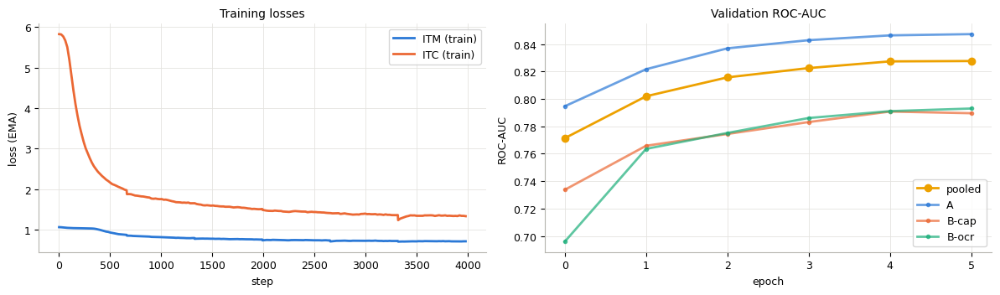

In [19]:
HEAD_KW = dict(img_dim=D_IMG, txt_dim=D_TXT, n_img_tokens=T_IMG, **CFG["HEAD"])
seed_everything()
head = mc.CrossAttentionHead(**HEAD_KW).to(DEVICE)
print(f"head parameters: {mc.count_parameters(head):,}")
opt = torch.optim.AdamW(head.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
TOTAL_STEPS = CFG["EPOCHS"] * STEPS_PER_EPOCH
def lr_lambda(step):
    if step < CFG["WARMUP_STEPS"]:
        return (step + 1) / CFG["WARMUP_STEPS"]
    return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - CFG["WARMUP_STEPS"]) / max(1, TOTAL_STEPS - CFG["WARMUP_STEPS"]))))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
itm_loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(CFG["POS_WEIGHT"], device=DEVICE))

CKPT_LAST, CKPT_BEST = CACHE / "ckpt" / "last.pt", CACHE / "ckpt" / "best_head.pt"
state = dict(epoch=0, best_auc=-1.0, bad_epochs=0, stopped=False,
             history=dict(step=[], itm=[], itc=[], lr=[], epoch=[], val_auc=[], val_auc_mode=[]))
if CKPT_LAST.exists():
    ck = torch.load(CKPT_LAST, map_location=DEVICE, weights_only=False)
    head.load_state_dict(ck["head"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); state = ck["state"]
    print(f"resumed from epoch {state['epoch']} (best val AUC {state['best_auc']:.4f})")

def val_auc(h):
    s = score_table(val_df, head=h)["main"]
    per_mode = {m: float(roc_auc_score(val_df.label[val_df["mode"] == m], s[(val_df["mode"] == m).values]))
                for m in MODE_NAMES if (val_df["mode"] == m).any()}
    return float(roc_auc_score(val_df.label, s)), per_mode

gstep = state["epoch"] * STEPS_PER_EPOCH
for epoch in range(state["epoch"], CFG["EPOCHS"]):
    if state["stopped"]:
        break
    plan = build_train_plan(epoch)
    kind_all = torch.from_numpy(np.concatenate([plan["kind"], plan["kind"]]))
    head.train(); t0 = time.time(); run_itm = run_itc = None
    for batch in make_train_loader(plan, need_tokens=True):
        s = batch["step"]; sl = slice(s * B, (s + 1) * B)
        itok = batch["tok"].to(DEVICE, non_blocking=True)
        ipool = batch["pool"].to(DEVICE, non_blocking=True).float()
        n = itok.shape[0]
        with torch.no_grad(), amp():
            ttok, tmask, tpool = mc.clip_text(clip, tok, plan["pos"][sl] + plan["neg"][sl], DEVICE, CFG["MAX_TEXT_TOKENS"])
        key = torch.from_numpy(plan["key"][sl]).to(DEVICE)
        dom = torch.from_numpy(plan["ds"][sl]).to(DEVICE)
        kind = torch.from_numpy(plan["kind"][sl]).to(DEVICE)
        kind2 = torch.cat([kind, kind])
        ar = torch.arange(n, device=DEVICE)
        with amp():
            img_p = head.proj_image(itok)
            txt_p = head.proj_text(ttok)
            zi, zt = head.itc_embed(img_p, txt_p[:n], tmask[:n])
            sim = head.scale() * (zi @ zt.T).float()
            same = key[:, None] == key[None, :]
            excl = same & ~torch.eye(n, dtype=torch.bool, device=DEVICE)
            l_itc = 0.5 * (F.cross_entropy(sim.masked_fill(excl, -1e4), ar) + F.cross_entropy(sim.T.masked_fill(excl.T, -1e4), ar))
            with torch.no_grad():
                invalid = same | ((dom[:, None] == 0) & (kind[None, :] == 1))
                w_i2t = torch.softmax(sim.detach().float().masked_fill(invalid, -float("inf")), 1)
                w_t2i = torch.softmax(sim.detach().float().T.masked_fill(invalid.T, -float("inf")), 1)
                for w, inv in ((w_i2t, invalid), (w_t2i, invalid.T)):
                    bad_rows = ~torch.isfinite(w).all(1) | (w.sum(1) <= 0)
                    if bad_rows.any():
                        w[bad_rows] = (~inv[bad_rows]).float() + 1e-6
                neg_txt = torch.multinomial(torch.nan_to_num(w_i2t, 0.0) + 1e-12, 1).squeeze(1)
                neg_img = torch.multinomial(torch.nan_to_num(w_t2i, 0.0) + 1e-12, 1).squeeze(1)
            ii = torch.cat([ar, ar, neg_img, ar])
            tt = torch.cat([ar, neg_txt, ar, ar + n])
            y = torch.cat([torch.ones(n, device=DEVICE), torch.zeros(3 * n, device=DEVICE)])
            cos = (ipool @ tpool.T)[ii, tt]
            mode_ids = torch.where(dom[ii] == 0, 0, torch.where(kind2.to(DEVICE)[tt] == 1, 2, 1))
            logit, _ = head.fuse(img_p[ii], txt_p[tt], tmask[tt], mode_ids, cos)
            l_itm = itm_loss_fn(logit.float(), y)
            loss = l_itm + CFG["ITC_WEIGHT"] * l_itc
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(head.parameters(), CFG["GRAD_CLIP"])
        scaler.step(opt); scaler.update(); sched.step(); gstep += 1
        run_itm = l_itm.item() if run_itm is None else 0.98 * run_itm + 0.02 * l_itm.item()
        run_itc = l_itc.item() if run_itc is None else 0.98 * run_itc + 0.02 * l_itc.item()
        if s % 20 == 0:
            H = state["history"]; H["step"].append(gstep); H["itm"].append(run_itm); H["itc"].append(run_itc)
            H["lr"].append(sched.get_last_lr()[0])
        if s % CFG["LOG_EVERY"] == 0:
            print(f"ep {epoch} step {s}/{STEPS_PER_EPOCH} | ITM {run_itm:.4f} ITC {run_itc:.4f} | "
                  f"lr {sched.get_last_lr()[0]:.2e} | temp {1 / head.scale().item():.4f} | {time.time() - t0:.0f}s", flush=True)
            log_mem("train")
    auc, auc_mode = val_auc(head)
    H = state["history"]; H["epoch"].append(epoch); H["val_auc"].append(auc); H["val_auc_mode"].append(auc_mode)
    improved = auc > state["best_auc"] + 1e-5
    if improved:
        state["best_auc"], state["bad_epochs"] = auc, 0
        torch.save(head.state_dict(), CKPT_BEST)
    else:
        state["bad_epochs"] += 1
        state["stopped"] = state["bad_epochs"] >= CFG["PATIENCE"]
    state["epoch"] = epoch + 1
    torch.save(dict(head=head.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                    state=state), CKPT_LAST)
    print(f"=== epoch {epoch}: val ROC-AUC {auc:.4f} {({k: round(v, 4) for k, v in auc_mode.items()})} "
          f"{'(best)' if improved else ''} | {time.time() - t0:.0f}s", flush=True)
    if state["stopped"]:
        print(f"early stopping: no improvement for {CFG['PATIENCE']} epochs")

head.load_state_dict(torch.load(CKPT_BEST, map_location=DEVICE, weights_only=True))
head.eval()
torch.save({k: v.detach().float().cpu() for k, v in head.state_dict().items()}, OUT / "head.pt")
print(f"best val ROC-AUC {state['best_auc']:.4f} -> saved {OUT / 'head.pt'}")

H = state["history"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(H["step"], H["itm"], label="ITM (train)", color=PALETTE[0])
axes[0].plot(H["step"], H["itc"], label="ITC (train)", color=PALETTE[1])
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss (EMA)"); axes[0].legend(); axes[0].set_title("Training losses")
axes[1].plot(H["epoch"], H["val_auc"], marker="o", label="pooled", color=PALETTE[3])
for j, m in enumerate(MODE_NAMES):
    axes[1].plot(H["epoch"], [d.get(m, np.nan) for d in H["val_auc_mode"]], marker=".", label=m, color=PALETTE[j], alpha=0.7)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("ROC-AUC"); axes[1].legend(); axes[1].set_title("Validation ROC-AUC")
savefig(fig, "loss_curves.png")

## 16. Calibration and thresholds (val only)

Per mode: val split by image into V1/V2 → Platt and isotonic fitted on V1 → the one with lower 15-bin ECE on V2
is refitted on all of val. Stored as plain JSON (`{a, b}` or `{x, y}` applied with `np.interp`) — no pickles.
Thresholds maximise F1 on the calibrated val probability. The same procedure is applied to all four models.

Cross-attention head — VAL
 mode     n  roc_auc     f1    acc    ece    thr
    A 30000   0.8472 0.7956 0.7611 0.0000 0.3993
B-cap 13170   0.7895 0.7535 0.7021 0.0136 0.4009
B-ocr  4166   0.7930 0.7411 0.7026 0.0000 0.3763
calibration: {'A': ('isotonic', {'platt': 0.01254, 'isotonic': 0.01121}), 'B-cap': ('platt', {'platt': 0.01351, 'isotonic': 0.02558}), 'B-ocr': ('isotonic', {'platt': 0.04958, 'isotonic': 0.02812})}
thresholds: {'A': 0.3993, 'B-cap': 0.4009, 'B-ocr': 0.3763}


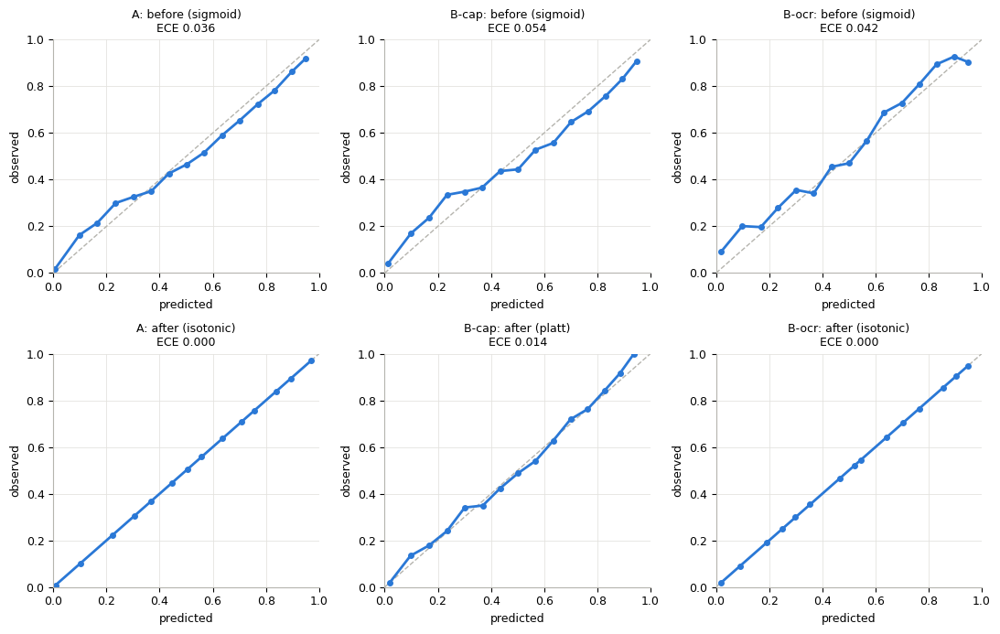

config.json written


In [20]:
VAL_SCORES["main"] = score_table(val_df, head=head)["main"]
CAL["main"], THR["main"] = tune(VAL_SCORES["main"], val_df)
summarize(VAL_SCORES["main"], val_df, CAL["main"], THR["main"], "Cross-attention head — VAL")
save_json({m: CAL["main"][m] for m in MODE_NAMES}, OUT / "calibration.json")
save_json({m: THR["main"][m] for m in MODE_NAMES}, OUT / "thresholds.json")
print("calibration:", {m: (CAL["main"][m]["method"], CAL["main"][m].get("ece_v2")) for m in MODE_NAMES})
print("thresholds:", {m: round(THR["main"][m], 4) for m in MODE_NAMES})

def reliability(ax, p, y, title, bins=CFG["ECE_BINS"]):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    xs = [p[idx == b].mean() for b in range(bins) if (idx == b).any()]
    ys = [y[idx == b].mean() for b in range(bins) if (idx == b).any()]
    ax.plot([0, 1], [0, 1], ls="--", color="#b5b4ae", lw=1)
    ax.plot(xs, ys, marker="o", color=PALETTE[0], ms=4)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("predicted"); ax.set_ylabel("observed")
    ax.set_title(f"{title}\nECE {ece_score(p, y):.3f}", fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for j, mode in enumerate(MODE_NAMES):
    m = (val_df["mode"] == mode).values
    if not m.any():
        continue
    y = val_df.label.values[m]
    reliability(axes[0, j], mc.sigmoid(VAL_SCORES["main"][m]), y, f"{mode}: before (sigmoid)")
    reliability(axes[1, j], mc.apply_calibration(VAL_SCORES["main"][m], CAL["main"][mode]), y,
                f"{mode}: after ({CAL['main'][mode]['method']})")
savefig(fig, "reliability_val.png")

def write_config():
    cfg = dict(
        clip_id=CFG["CLIP_ID"], clip_dims=DIMS, head_kwargs=HEAD_KW, head_parameters=mc.count_parameters(head),
        modes=mc.MODES, image=CFG["IMAGE"], max_text_tokens=CFG["MAX_TEXT_TOKENS"],
        ocr=dict(CFG["OCR"], engine="easyocr", training_ocr_source=OCR_SOURCE_USED),
        cleaning=dict(unicode="NFKC", collapse_whitespace=True, min_words_training=CFG["MIN_WORDS"]),
        seed=SEED, training={k: CFG[k] for k in ("BATCH", "MIX_COCO", "LR", "WEIGHT_DECAY", "WARMUP_STEPS", "EPOCHS",
                                                 "PATIENCE", "ITC_WEIGHT", "POS_WEIGHT", "GRAD_CLIP", "OCR_NOISE_P",
                                                 "OCR_NOISE_RATE", "HARD_TOPK", "HARD_POOL", "FN_TEXT_COS",
                                                 "TEXTSWAP_POOL", "TC_VAL_FRAC")},
        trained_epochs=state["epoch"], best_val_roc_auc=state["best_auc"], early_stopped=state["stopped"],
        swap_vocab=CFG["SWAP_GROUPS"], swap_rules=CFG["SWAP_RULES"],
        calibration_ece_bins=CFG["ECE_BINS"], data_sources=CFG["URLS"], library_versions=VERSIONS,
        mismatch_core_version=mc.__version__,
        mismatch_core_sha256=hashlib.sha256((OUT / "mismatch_core.py").read_bytes()).hexdigest(),
    )
    save_json(cfg, OUT / "config.json")
    return cfg
_ = write_config()
print("config.json written")

## 17. Final test evaluation (run once)

All four models are scored on the **same frozen test tables** in a single pass, using thresholds and calibration
fitted on val. Per-type metrics use the positives of that mode vs. that negative type only.

**Circularity note.** `hard` negatives are mined with CLIP similarity, which disadvantages the cosine baseline by
construction. `swapped` negatives are model-independent and are the fairest comparison.

TEST ROC-AUC (rows = models, columns = mode × negative type):
mode                 A                         B-cap                          B-ocr          
type              easy   hard overall swapped   easy   hard overall swapped overall text_swap
model                                                                                        
CLIP cosine      0.996  0.441   0.700   0.689  0.981  0.323   0.607   0.575   0.729     0.729
LogReg           0.950  0.564   0.739   0.718  0.873  0.509   0.668   0.657   0.537     0.537
MLP              0.987  0.599   0.778   0.766  0.948  0.590   0.724   0.647   0.740     0.740
Cross-attn head  0.996  0.704   0.849   0.863  0.974  0.641   0.776   0.733   0.793     0.793

TEST F1 at val-tuned threshold:
mode                 A                         B-cap                          B-ocr          
type              easy   hard overall swapped   easy   hard overall swapped overall text_swap
model                                                      

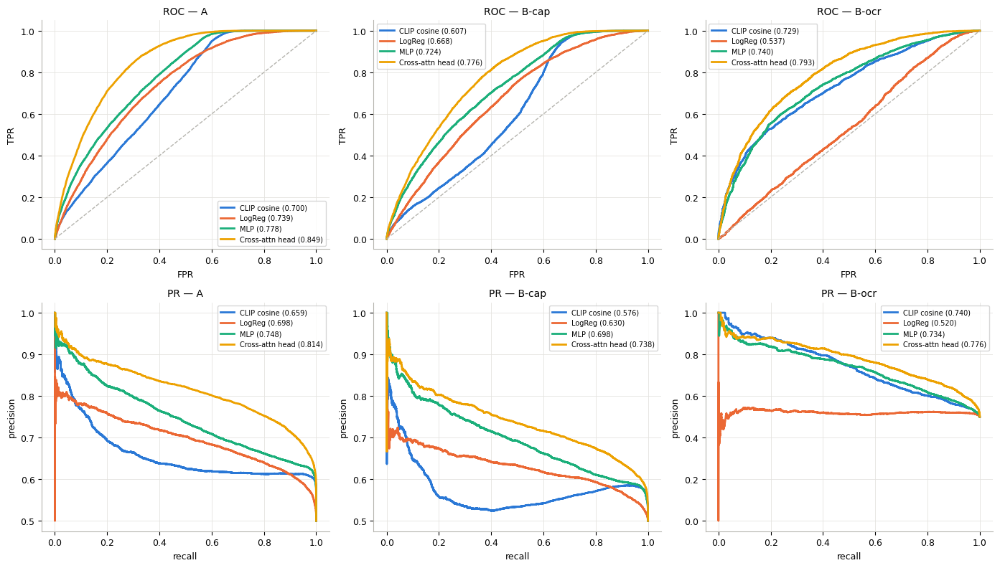

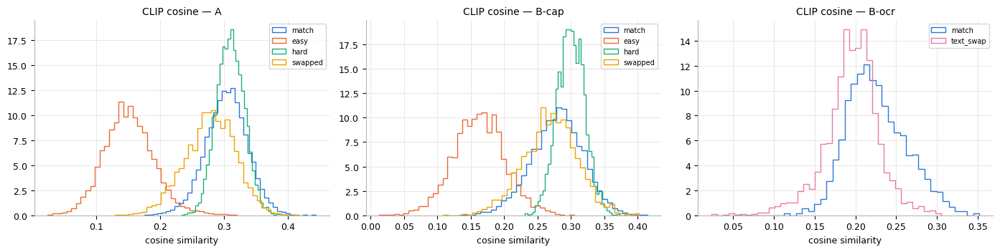

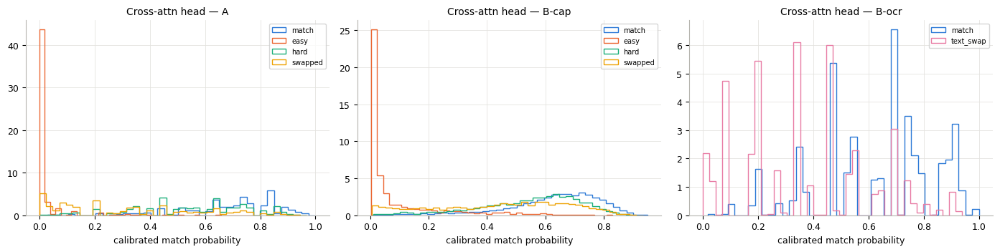

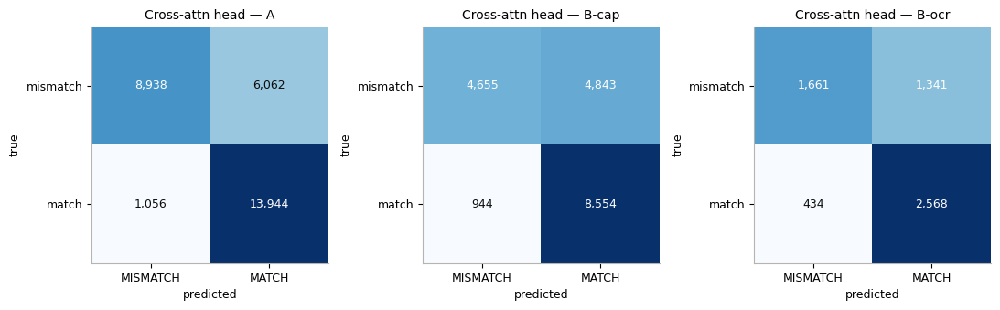

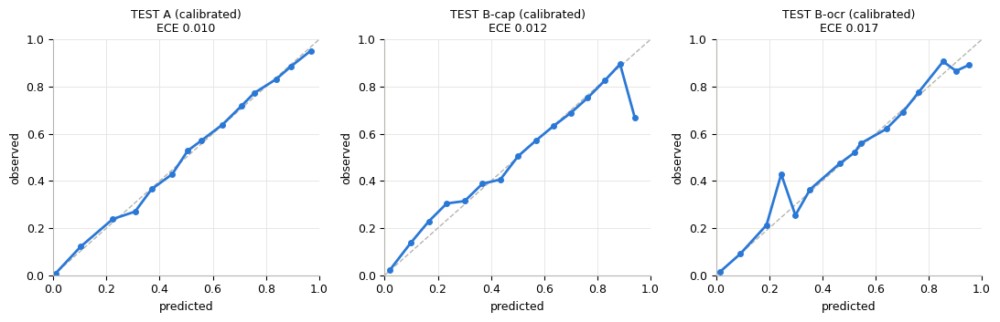

In [21]:
_t = score_table(test_df, head=head, feat_models=BASELINES)
TEST_SCORES = {"cosine": _t["cos"], "logreg": _t["logreg"], "mlp": _t["mlp"], "main": _t["main"]}
np.savez(PAIR_DIR / "test_scores.npz", **TEST_SCORES)
y_test = test_df.label.values
TEST_PROB = {k: np.zeros(len(test_df)) for k in MODEL_NAMES}
for k in MODEL_NAMES:
    for mode in MODE_NAMES:
        m = (test_df["mode"] == mode).values
        TEST_PROB[k][m] = mc.apply_calibration(TEST_SCORES[k][m], CAL[k][mode])

METRICS = {"test": {}, "val_thresholds": THR, "calibration_methods": {k: {m: CAL[k][m]["method"] for m in MODE_NAMES} for k in MODEL_NAMES}}
table_rows = []
for k in MODEL_NAMES:
    METRICS["test"][k] = {}
    for mode in MODE_NAMES:
        mm_ = (test_df["mode"] == mode).values
        if not mm_.any():
            continue
        res = {"overall": binary_metrics(TEST_PROB[k][mm_], y_test[mm_], THR[k][mode], score=TEST_SCORES[k][mm_])}
        for t in sorted(test_df.loc[mm_ & (y_test == 0), "neg_type"].unique()):
            sel = mm_ & ((y_test == 1) | (test_df.neg_type.values == t))
            res[t] = binary_metrics(TEST_PROB[k][sel], y_test[sel], THR[k][mode], score=TEST_SCORES[k][sel])
        METRICS["test"][k][mode] = res
        for t, r in res.items():
            table_rows.append(dict(model=MODEL_LABEL[k], mode=mode, type=t, roc_auc=r["roc_auc"], f1=r["f1"]))
res_df = pd.DataFrame(table_rows)
main_table = res_df.pivot_table(index="model", columns=["mode", "type"], values=["roc_auc", "f1"]).reindex(
    [MODEL_LABEL[k] for k in MODEL_NAMES])
main_table.to_csv(FIG / "main_results_table.csv")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("TEST ROC-AUC (rows = models, columns = mode × negative type):")
print(main_table["roc_auc"].round(3).to_string())
print("\nTEST F1 at val-tuned threshold:")
print(main_table["f1"].round(3).to_string())
save_json(METRICS, OUT / "metrics.json")

# ---- figures: ROC / PR per mode, similarity histograms, confusion matrices, test reliability ----
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, mode in enumerate(MODE_NAMES):
    mm_ = (test_df["mode"] == mode).values
    if not mm_.any():
        continue
    for k in MODEL_NAMES:
        fpr, tpr, _ = roc_curve(y_test[mm_], TEST_SCORES[k][mm_])
        pr, rc, _ = precision_recall_curve(y_test[mm_], TEST_SCORES[k][mm_])
        auc_ = METRICS["test"][k][mode]["overall"]["roc_auc"]; ap_ = METRICS["test"][k][mode]["overall"]["pr_auc"]
        axes[0, j].plot(fpr, tpr, color=MODEL_COLOR[k], label=f"{MODEL_LABEL[k]} ({auc_:.3f})")
        axes[1, j].plot(rc, pr, color=MODEL_COLOR[k], label=f"{MODEL_LABEL[k]} ({ap_:.3f})")
    axes[0, j].plot([0, 1], [0, 1], ls="--", color="#b5b4ae", lw=1)
    axes[0, j].set_title(f"ROC — {mode}"); axes[0, j].set_xlabel("FPR"); axes[0, j].set_ylabel("TPR"); axes[0, j].legend(fontsize=7)
    axes[1, j].set_title(f"PR — {mode}"); axes[1, j].set_xlabel("recall"); axes[1, j].set_ylabel("precision"); axes[1, j].legend(fontsize=7)
savefig(fig, "roc_pr_test.png")

TYPE_COLOR = {"pos": PALETTE[0], "easy": PALETTE[1], "hard": PALETTE[2], "swapped": PALETTE[3], "text_swap": PALETTE[4]}
for score_name, scores, xlabel, fname in (("CLIP cosine", TEST_SCORES["cosine"], "cosine similarity", "hist_cosine_test.png"),
                                          ("Cross-attn head", TEST_PROB["main"], "calibrated match probability", "hist_main_prob_test.png")):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for j, mode in enumerate(MODE_NAMES):
        mm_ = (test_df["mode"] == mode).values
        for t in [t for t in TYPE_COLOR if (mm_ & (test_df.neg_type.values == t)).any()]:
            sel = mm_ & (test_df.neg_type.values == t)
            axes[j].hist(scores[sel], bins=40, histtype="step", lw=1.8, density=True, color=TYPE_COLOR[t],
                         label="match" if t == "pos" else t)
        axes[j].set_title(f"{score_name} — {mode}"); axes[j].set_xlabel(xlabel); axes[j].legend(fontsize=7)
    savefig(fig, fname)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for j, mode in enumerate(MODE_NAMES):
    if mode not in METRICS["test"]["main"]:
        continue
    cm = np.array(METRICS["test"]["main"][mode]["overall"]["confusion"])
    axes[j].imshow(cm, cmap="Blues")
    for (a, b_), v in np.ndenumerate(cm):
        axes[j].text(b_, a, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "#0b0b0b")
    axes[j].set_xticks([0, 1], ["MISMATCH", "MATCH"]); axes[j].set_yticks([0, 1], ["mismatch", "match"])
    axes[j].set_xlabel("predicted"); axes[j].set_ylabel("true"); axes[j].set_title(f"Cross-attn head — {mode}"); axes[j].grid(False)
savefig(fig, "confusion_test.png")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for j, mode in enumerate(MODE_NAMES):
    mm_ = (test_df["mode"] == mode).values
    if mm_.any():
        reliability(axes[j], TEST_PROB["main"][mm_], y_test[mm_], f"TEST {mode} (calibrated)")
savefig(fig, "reliability_test.png")

## 18. Error analysis (main model, test)

false positives: 12,246 | false negatives: 2,434


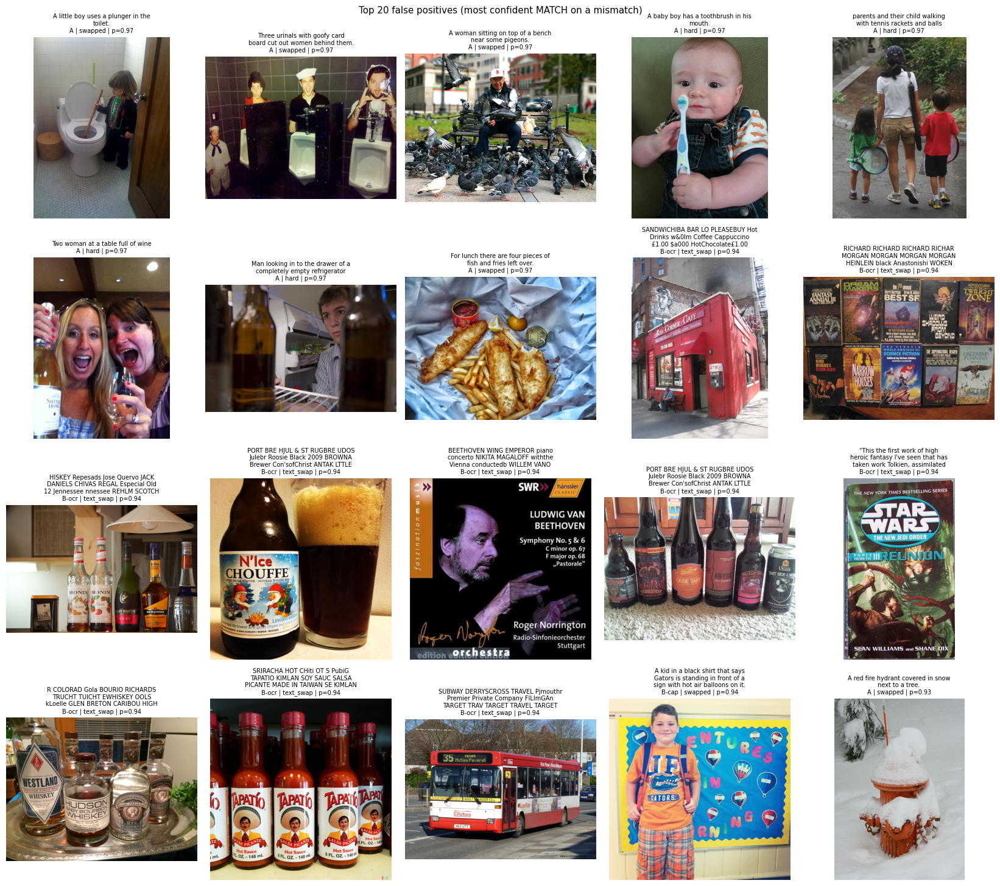

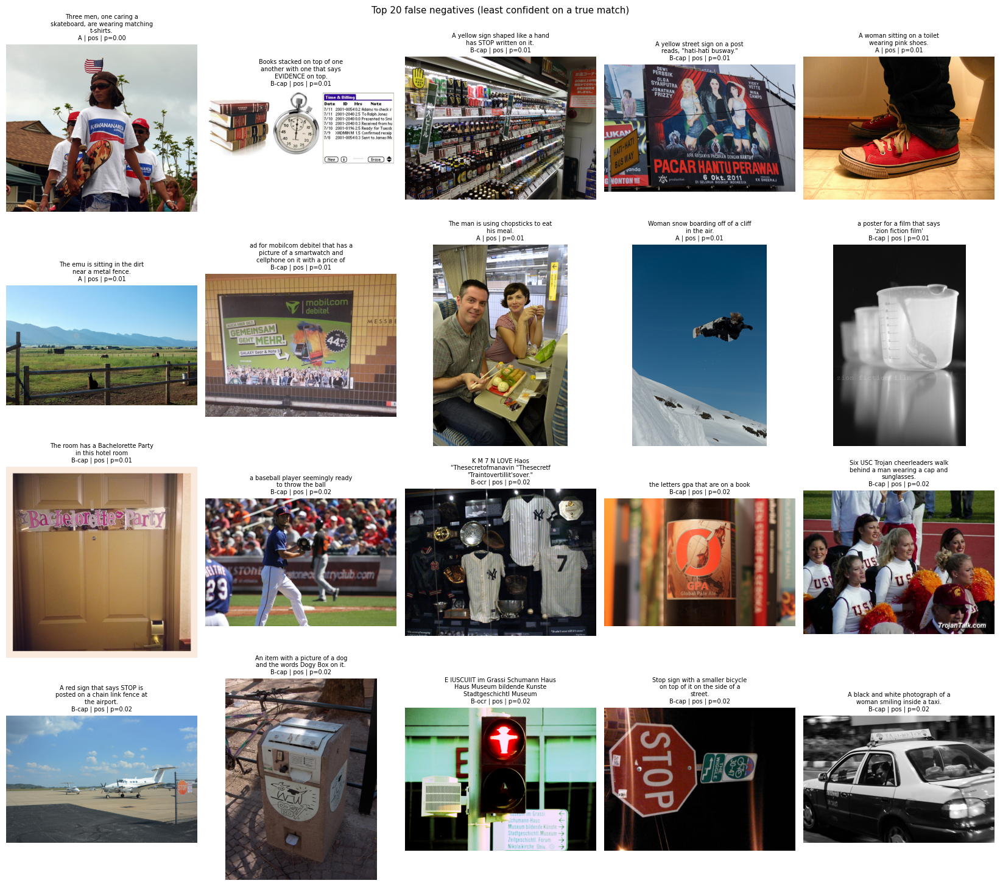

Swapped negatives accepted as MATCH, by swap group:
                n  false_positives  fp_rate
swap_group                                
animal       809              183    0.226
color       2416             1470    0.608
food         402               97    0.241
number       887              530    0.598
people      1664              603    0.362
vehicle      750              263    0.351

False-positive rate by mode × negative type:
                     n    fp  fp_rate
mode  neg_type                      
A     easy       5000    77    0.015
      hard       5506  4316    0.784
      swapped    4494  1669    0.371
B-cap easy       3166   224    0.071
      hard       3898  3142    0.806
      swapped    2434  1477    0.607
B-ocr text_swap  3002  1341    0.447


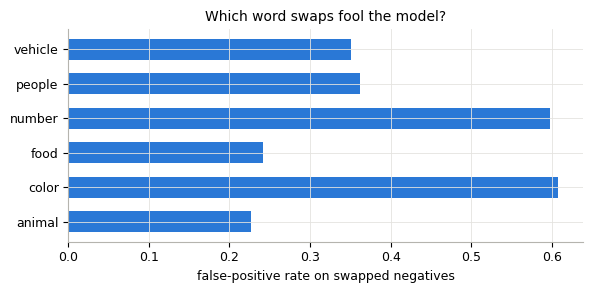

In [22]:
ea = test_df.assign(prob=TEST_PROB["main"], thr=test_df["mode"].map(THR["main"]))
ea["pred"] = (ea.prob >= ea.thr).astype(int)
fp = ea[(ea.label == 0) & (ea.pred == 1)].sort_values("prob", ascending=False).head(CFG["N_ERRORS"])
fn = ea[(ea.label == 1) & (ea.pred == 0)].sort_values("prob", ascending=True).head(CFG["N_ERRORS"])
print(f"false positives: {int(((ea.label == 0) & (ea.pred == 1)).sum()):,} | false negatives: {int(((ea.label == 1) & (ea.pred == 0)).sum()):,}")

def show_errors(df, title, fname):
    if df.empty:
        print(f"{title}: none"); return
    cols = 5; rows_ = math.ceil(len(df) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(3.3 * cols, 3.7 * rows_), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), df.iterrows()):
        ax.imshow(load_pil(IMG[r.ds].iloc[r.img_idx]))
        ax.set_title("\n".join(textwrap.wrap(r.text, 34)[:3]) + f"\n{r['mode']} | {r.neg_type} | p={r.prob:.2f}", fontsize=7)
    fig.suptitle(title)
    savefig(fig, fname)

show_errors(fp, f"Top {len(fp)} false positives (most confident MATCH on a mismatch)", "errors_false_positives.png")
show_errors(fn, f"Top {len(fn)} false negatives (least confident on a true match)", "errors_false_negatives.png")

sw = ea[ea.neg_type == "swapped"]
by_group = sw.groupby("swap_group").agg(n=("label", "size"), false_positives=("pred", "sum"))
by_group["fp_rate"] = by_group.false_positives / by_group.n
by_type = ea[ea.label == 0].groupby(["mode", "neg_type"]).agg(n=("pred", "size"), fp=("pred", "sum"))
by_type["fp_rate"] = by_type.fp / by_type.n
print("Swapped negatives accepted as MATCH, by swap group:\n", by_group.round(3).to_string())
print("\nFalse-positive rate by mode × negative type:\n", by_type.round(3).to_string())
by_group.to_csv(FIG / "errors_by_swap_group.csv"); by_type.to_csv(FIG / "errors_by_negative_type.csv")
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(by_group.index, by_group.fp_rate, color=PALETTE[0], height=0.6)
ax.set_xlabel("false-positive rate on swapped negatives"); ax.set_title("Which word swaps fool the model?")
savefig(fig, "errors_by_swap_group.png")
METRICS["error_analysis"] = dict(
    n_false_positives=int(((ea.label == 0) & (ea.pred == 1)).sum()), n_false_negatives=int(((ea.label == 1) & (ea.pred == 0)).sum()),
    swapped_by_group=by_group.reset_index().to_dict("records"),
    fp_by_mode_type=by_type.reset_index().to_dict("records"),
    top_false_positives=fp[["pair_id", "mode", "neg_type", "swap_group", "text", "prob"]].to_dict("records"),
    top_false_negatives=fn[["pair_id", "mode", "text", "prob"]].to_dict("records"),
)
save_json(METRICS, OUT / "metrics.json")

## 19. `predict()` demo, CPU latency, EasyOCR gap check

The backend contract is exercised on **CPU** exactly as the web app will call it. Four scenarios: plain photo +
caption (`A`), text photo + caption (`B-cap` + `B-ocr`), text photo without caption (`B-ocr` only), and plain photo
without caption (`NoTextInputError`).

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


demo images: COCO without detected text [119470, 121665] | TextCaps with detected text [25058, 22530, 24811, 22767]
--- A: plain photo + caption
{
 "text_detected": false,
 "ocr_text": "",
 "results": [
  {
   "source": "user",
   "text": "A standing toilet hole filled with nasty filthy.",
   "mode": "A",
   "similarity": 0.29787,
   "match_probability": 0.850435,
   "threshold": 0.399293,
   "verdict": "MATCH"
  },
  {
   "source": "user",
   "text": "a plate of food on a table",
   "mode": "A",
   "similarity": 0.16912,
   "match_probability": 0.023585,
   "threshold": 0.399293,
   "verdict": "MISMATCH"
  }
 ]
}
--- B: text photo + caption
{
 "text_detected": true,
 "ocr_text": "Mozilla Firelox LEGOBLOGGEN Bakhallet vid Mirror Falls",
 "results": [
  {
   "source": "user",
   "text": "Lego blog website with the name of the blog across the top banner and a lego diorama in the center flanked on both sides by links and information.",
   "mode": "B-cap",
   "similarity": 0.308135,
   "ma

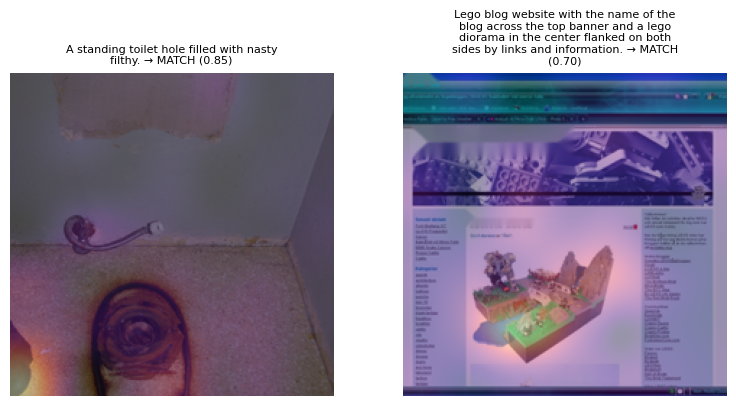

CPU latency (ms): {'median': 9295.270486500158, 'p90': 9426.651272199524, 'runs': 20, 'image_size': [1024, 618], 'n_captions': 1, 'torch_threads': 4, 'includes': 'EasyOCR + masking + CLIP + head'}
EasyOCR found text on 405/500 test images that have official OCR
         official_ocr   easyocr
roc_auc       0.87501  0.814751
f1           0.810624  0.749133
accuracy     0.797531  0.732099
ece          0.057485    0.0876
drop (official − EasyOCR): {'roc_auc': 0.0603, 'f1': 0.0615, 'accuracy': 0.0654}


In [23]:
torch.set_num_threads(max(1, os.cpu_count() or 1))
predictor = mc.Predictor(OUT, device="cpu")
cpu_reader = predictor.reader                  # EasyOCR on CPU, same as the backend

def ocr_cached(r, reader=None, _cache={}):
    k = (r.dataset, r.image_id, id(reader))
    if k not in _cache:
        p = mc.Predictor.__new__(mc.Predictor); p.ocr_cfg, p._reader = CFG["OCR"], reader or cpu_reader
        _cache[k] = mc.Predictor.run_ocr(p, load_pil(r))
    return _cache[k]

def find_images(ds_code, want_text, n, need_caption=True, max_tries=200):
    split_imgs = imgs_in[(ds_code, "test")] if need_caption else ocr_imgs_in["test"]
    if ds_code == 1:
        split_imgs = np.intersect1d(split_imgs, ocr_imgs_in["test"])
    out = []
    for i in np.random.default_rng(SEED).permutation(split_imgs)[:max_tries]:
        r = IMG[ds_code].iloc[int(i)]
        if ocr_cached(r)["has_text"] == want_text:
            out.append(int(i))
            if len(out) == n:
                break
    return out

def pretty(res):
    return json.dumps({**res, "results": [{k: v for k, v in x.items() if k != "heatmap"} for x in res["results"]]}, indent=1)

coco_plain = find_images(0, want_text=False, n=2)
tc_text = find_images(1, want_text=True, n=4)
print("demo images: COCO without detected text", coco_plain, "| TextCaps with detected text", tc_text)
scen = {}
if coco_plain:
    r = IMG[0].iloc[coco_plain[0]]; cap_true = CAP_TEXT[caps_by_img[0][r.img_idx][0]]
    scen["A: plain photo + caption"] = (r, [cap_true, swap_caption(cap_true, random.Random(0))[0] if swap_caption(cap_true, random.Random(0)) else "a plate of food on a table"])
if tc_text:
    r = IMG[1].iloc[tc_text[0]]; scen["B: text photo + caption"] = (r, [CAP_TEXT[caps_by_img[1][r.img_idx][0]]])
    scen["B-ocr only: text photo, no caption"] = (r, [])
for name, (r, cs) in scen.items():
    res = predictor.predict(load_pil(r), cs, ocr_result=ocr_cached(r))
    print(f"--- {name}\n{pretty(res)}")
if coco_plain:
    try:
        predictor.predict(load_pil(IMG[0].iloc[coco_plain[0]]), [], ocr_result=ocr_cached(IMG[0].iloc[coco_plain[0]]))
        raise AssertionError("expected NoTextInputError")
    except mc.NoTextInputError as e:
        print("--- plain photo, no caption -> NoTextInputError:", e)

# heatmap overlay for the first two scenarios
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (name, (r, cs)) in zip(axes, list(scen.items())[:2]):
    res = predictor.predict(load_pil(r), cs, ocr_result=ocr_cached(r))
    top = res["results"][0]
    im = mc.prepare_image(load_pil(r), ocr_cached(r)["boxes"] or None, IMG_CFG)
    hm = cv2.resize(np.array(top["heatmap"], np.float32), (im.shape[1], im.shape[0]), interpolation=cv2.INTER_CUBIC)
    ax.imshow(im); ax.imshow(hm, cmap="magma", alpha=0.45); ax.axis("off")
    ax.set_title("\n".join(textwrap.wrap(f"{top['text']} → {top['verdict']} ({top['match_probability']:.2f})", 40)), fontsize=8)
savefig(fig, "heatmap_demo.png")

# ---- CPU latency: full predict() incl. EasyOCR, median of N runs ----
lat_row, lat_caps = (scen.get("B: text photo + caption") or next(iter(scen.values())))
lat_img = load_pil(lat_row)
predictor.predict(lat_img, lat_caps)                          # warm-up
times = []
for _ in range(CFG["LATENCY_RUNS"]):
    t0 = time.perf_counter(); predictor.predict(lat_img, lat_caps); times.append(time.perf_counter() - t0)
times_ms = np.array(times) * 1000
METRICS["cpu_latency_ms"] = dict(median=float(np.median(times_ms)), p90=float(np.percentile(times_ms, 90)),
                                 runs=len(times_ms), image_size=list(lat_img.size), n_captions=len(lat_caps),
                                 torch_threads=torch.get_num_threads(), includes="EasyOCR + masking + CLIP + head")
print("CPU latency (ms):", METRICS["cpu_latency_ms"])

# ---- EasyOCR gap check: B-ocr on TextCaps test with EasyOCR instead of official OCR ----
gap_reader = get_reader()                                      # GPU EasyOCR for speed; same settings as the Predictor
gap_imgs = np.random.default_rng(SEED).permutation(ocr_imgs_in["test"])[:CFG["GAP_N"]]
eo_res = {int(i): ocr_cached(IMG[1].iloc[int(i)], reader=gap_reader) for i in gap_imgs}
kept = np.array([i for i in gap_imgs if eo_res[int(i)]["has_text"]], dtype=np.int64)
print(f"EasyOCR found text on {len(kept)}/{len(gap_imgs)} test images that have official OCR")

@torch.no_grad()
def score_bocr(img_tok, img_pool, texts):
    out = []
    for s in range(0, len(texts), CFG["SCORE_BATCH"]):
        it = img_tok[s:s + CFG["SCORE_BATCH"]].to(DEVICE); ip = img_pool[s:s + CFG["SCORE_BATCH"]].to(DEVICE).float()
        with amp():
            tt, tm, tp = mc.clip_text(clip, tok, texts[s:s + CFG["SCORE_BATCH"]], DEVICE, CFG["MAX_TEXT_TOKENS"])
            cos = (ip * tp).sum(-1)
            lg, _ = head(it, tt, tm, torch.full((len(it),), mc.MODES["B-ocr"], device=DEVICE), cos)
        out.append(lg.float().cpu().numpy())
    return np.concatenate(out) if out else np.zeros(0)

if len(kept) >= 4:
    perm = np.roll(np.arange(len(kept)), 1)                    # derangement: each image gets another image's text
    # official OCR: masked-with-official-boxes tokens from the cache + official strings
    tok_off = torch.from_numpy(gather("tok", np.ones(len(kept), int), kept))
    pool_off = torch.from_numpy(gather("pool", np.ones(len(kept), int), kept))
    txt_off = [OCR_TEXT[i] for i in kept]
    # EasyOCR: re-mask with EasyOCR boxes and re-encode the images
    u8 = np.stack([mc.prepare_image(load_pil(IMG[1].iloc[int(i)]), eo_res[int(i)]["boxes"], IMG_CFG) for i in kept])
    tk_l, pl_l = [], []
    for s in range(0, len(u8), CFG["EXTRACT_BATCH"]):
        with amp():
            tk, pl = mc.clip_image(clip, mc.normalize_pixels(torch.from_numpy(u8[s:s + CFG["EXTRACT_BATCH"]]).to(DEVICE)))
        tk_l.append(tk.half().cpu()); pl_l.append(pl.half().cpu())
    tok_eo, pool_eo = torch.cat(tk_l), torch.cat(pl_l)
    txt_eo = [eo_res[int(i)]["text"] for i in kept]
    gap = {}
    for name, (tk, pl, txt) in {"official_ocr": (tok_off, pool_off, txt_off), "easyocr": (tok_eo, pool_eo, txt_eo)}.items():
        lg = np.concatenate([score_bocr(tk, pl, txt), score_bocr(tk, pl, [txt[j] for j in perm])])
        yy = np.concatenate([np.ones(len(kept)), np.zeros(len(kept))])
        pp = mc.apply_calibration(lg, CAL["main"]["B-ocr"])
        gap[name] = binary_metrics(pp, yy, THR["main"]["B-ocr"], score=lg)
    gap["drop"] = {k: gap["official_ocr"][k] - gap["easyocr"][k] for k in ("roc_auc", "f1", "accuracy")}
    gap["n_images"] = int(len(kept)); gap["easyocr_detection_rate"] = float(len(kept) / max(1, len(gap_imgs)))
    METRICS["easyocr_gap"] = gap
    print(pd.DataFrame({k: gap[k] for k in ("official_ocr", "easyocr")}).loc[["roc_auc", "f1", "accuracy", "ece"]].round(4))
    print("drop (official − EasyOCR):", {k: round(v, 4) for k, v in gap["drop"].items()})
else:
    METRICS["easyocr_gap"] = {"note": "too few images with EasyOCR text for the gap check", "n_images": int(len(kept))}
save_json(METRICS, OUT / "metrics.json")

## 20. Golden predictions for backend tests

2 COCO test images and 4 TextCaps test images (2 with captions, 2 OCR-only). The original image bytes are saved,
`predict()` is run on CPU through a **fresh** `Predictor` loaded from `model_outputs/`, and the outputs are stored.
The backend must reproduce every `match_probability` within ±0.01.

In [24]:
GOLD = OUT / "golden"
golden_cases = []
def add_golden(ds_code, img_i, captions_, tag):
    r = IMG[ds_code].iloc[img_i]
    ext = Path(r.member).suffix.lower() or ".jpg"
    fname = f"{tag}_{r.dataset}_{r.image_id}{ext}"
    (GOLD / fname).write_bytes(zip_read(r.zip_key, r.member))       # original bytes, no re-encoding
    golden_cases.append(dict(file=fname, captions=captions_, dataset=r.dataset, image_id=r.image_id))

for j, i in enumerate(coco_plain[:2]):
    cs = caps_by_img[0][i]
    swp = swap_caption(CAP_TEXT[cs[0]], random.Random(j))
    add_golden(0, i, [CAP_TEXT[cs[0]]] + ([swp[0]] if swp else []), f"coco{j + 1}")
for j, i in enumerate(tc_text[:2]):
    cs = caps_by_img[1][i]
    other = CAP_TEXT[caps_by_img[1][tc_text[-1 - j]][0]] if len(tc_text) > 1 else "a photo of a street"
    add_golden(1, i, [CAP_TEXT[cs[0]], other], f"textcaps_cap{j + 1}")
for j, i in enumerate(tc_text[2:4]):
    add_golden(1, i, [], f"textcaps_ocronly{j + 1}")
if coco_plain:
    golden_cases.append(dict(golden_cases[0], captions=[], expect_error="NoTextInputError"))

fresh = mc.Predictor(OUT, device="cpu", ocr_reader=cpu_reader)
for case in golden_cases:
    img = Image.open(GOLD / case["file"])
    try:
        case["expected"] = fresh.predict(img, case["captions"])
    except mc.NoTextInputError as e:
        case["expected"] = {"error": "NoTextInputError", "message": str(e)}
save_json({"tolerance": 0.01, "device": "cpu", "notes": "Run Predictor(artifacts_dir, device='cpu').predict(Image.open(file), captions)",
           "cases": golden_cases}, GOLD / "golden_predictions.json")

# reproducibility self-check with a second fresh Predictor (what the backend test will do)
again = mc.Predictor(OUT, device="cpu")
max_dev = 0.0
for case in golden_cases:
    if "error" in case["expected"]:
        try:
            again.predict(Image.open(GOLD / case["file"]), case["captions"]); raise AssertionError("expected error")
        except mc.NoTextInputError:
            continue
    got = again.predict(Image.open(GOLD / case["file"]), case["captions"])
    exp = {(x["source"], x["text"]): x["match_probability"] for x in case["expected"]["results"]}
    for x in got["results"]:
        max_dev = max(max_dev, abs(x["match_probability"] - exp[(x["source"], x["text"])]))
print(f"golden cases: {len(golden_cases)} | max |Δprob| on reload: {max_dev:.6f}")
assert max_dev <= 0.01
for case in golden_cases:
    e = case["expected"]
    print(case["file"], "->", e.get("error") or [(x["mode"], x["verdict"], x["match_probability"]) for x in e["results"]])

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


golden cases: 7 | max |Δprob| on reload: 0.000000
coco1_coco_220446.jpg -> [('A', 'MATCH', 0.850435)]
coco2_coco_451683.jpg -> [('A', 'MATCH', 0.834821), ('A', 'MATCH', 0.399293)]
textcaps_cap1_tc_fa54ccee9f535366.jpg -> [('B-cap', 'MATCH', 0.695861), ('B-ocr', 'MATCH', 0.542484), ('B-cap', 'MISMATCH', 0.045353)]
textcaps_cap2_tc_1643223e99fad9fa.jpg -> [('B-cap', 'MATCH', 0.776751), ('B-ocr', 'MATCH', 0.527027), ('B-cap', 'MISMATCH', 0.063538)]
textcaps_ocronly1_tc_e0994cf4679fe93b.jpg -> [('B-ocr', 'MATCH', 0.546154)]
textcaps_ocronly2_tc_2659571273d85bbd.jpg -> [('B-ocr', 'MATCH', 0.702882)]
coco1_coco_220446.jpg -> NoTextInputError


## 21. Save artifacts, zip, manifest

After the committed run finishes: **Output** tab → download `model_outputs.zip` → unzip into
`backend/model_outputs/`. CLIP weights are not included; the backend loads `openai/clip-vit-base-patch32` by the
name in `config.json`.

In [25]:
cfg_final = write_config()
METRICS["summary"] = {k: {m: {t: {"roc_auc": v.get("roc_auc"), "f1": v.get("f1")} for t, v in d.items()}
                          for m, d in METRICS["test"][k].items()} for k in MODEL_NAMES}
METRICS["counts"] = dict(test_pairs=int(len(test_df)), val_pairs=int(len(val_df)),
                         images={f"{DS_NAME[c]}/{s}": int(len(v)) for (c, s), v in imgs_in.items()})
save_json(METRICS, OUT / "metrics.json")

req = [f"torch=={torch.__version__.split('+')[0]}", f"transformers=={transformers.__version__}",
       f"easyocr=={VERSIONS['easyocr']}", f"opencv-python-headless=={cv2.__version__}", f"numpy=={np.__version__}",
       f"pillow=={PIL.__version__}"]
if "tokenizers" in VERSIONS:
    req.append(f"tokenizers=={VERSIONS['tokenizers']}")
try:
    import safetensors; req.append(f"safetensors=={safetensors.__version__}")
except Exception:
    pass
(OUT / "requirements_inference.txt").write_text("\n".join(req) + "\n")

# sanity: required artifacts present
REQUIRED = ["head.pt", "mismatch_core.py", "calibration.json", "thresholds.json", "config.json", "metrics.json",
            "requirements_inference.txt", "test_pairs.csv", "golden/golden_predictions.json"]
missing = [f for f in REQUIRED if not (OUT / f).exists()]
assert not missing, f"missing artifacts: {missing}"
assert len(list((OUT / "figures").glob("*.png"))) >= 8

zip_path = shutil.make_archive(CFG["ZIP_BASE"], "zip", OUT)
print("zip:", zip_path, f"{Path(zip_path).stat().st_size / 1e6:.1f} MB")
print("\nMANIFEST")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(OUT)!s:<55} {p.stat().st_size:>12,}  {hashlib.sha256(p.read_bytes()).hexdigest()}")

for k, h in list(_zip_handles.items()):
    h.close(); _zip_handles.pop(k)
if CFG["DELETE_ALL_ZIPS_AT_END"]:
    for k in ZIP_KEYS:
        if PATHS[k].exists():
            PATHS[k].unlink()
    print("raw zips deleted")
log_mem("end")
print("\nDone. Download model_outputs.zip from the notebook's Output tab.")

zip: /kaggle/working/model_outputs.zip 25.9 MB

MANIFEST
calibration.json                                               7,881  9409243ac26e6556d632c3a65fc915481127ce5d3d9f06cc6ccd03a8bc3e1180
config.json                                                    3,608  a19166813e7d1f7e4e414285090bf406a02934b2d024de7e77dee714d71dce39
figures/confusion_test.png                                    28,769  5eaca8548c1f14f26cbffea9fc8e0e4284e03022181db23cebef390a11f5fde5
figures/errors_by_negative_type.csv                              291  22c67f985f00bdf76eaed1e268b8ddd04d330b475e1ade2f203f26c1fef9d4b1
figures/errors_by_swap_group.csv                                 243  a1f221d4382aed70b0ac36c386bd6da07141a88257b8bb34354660e6ca02ce11
figures/errors_by_swap_group.png                              22,293  1b3b126e1d0685e7be092bfd971f0f284be3347a69dea45aa28b347d4b825007
figures/errors_false_negatives.png                         3,706,368  f2185f4224beb892803fdf51d7dcd95cd8ccd2c0ef4602fc0050283873d4808